# Examen Parcial - Informe 03 - Redes Neuronales Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo**
**Riveros Ruiz, Jason Wilmer**
**Torres Vela, Juan Carlos (Representante)**
**Zavala Suyo, Rafael**

---
**Prof. Dr.    Aldo Camargo**

---
# 03 · Generalización geográfica: cámaras vistas (cis) vs. cámaras nuevas (trans)

**Hipótesis a contrastar:** los detectores de cámaras trampa memorizan el **fondo** de cada cámara (roca, tronco, iluminación) y pierden desempeño al desplegarse en una ubicación nueva.

**Diseño experimental** (partición oficial `eccv_train` / `eccv_val`):
- Se entrena con cámaras de `eccv_train`.
- **cis_val**: secuencias reservadas de esas mismas cámaras → generalización *dentro* de ubicaciones conocidas.
- **trans_val**: cámaras de `eccv_val`, nunca vistas → generalización a *ubicaciones nuevas*.
- **Brecha de generalización** = métrica(cis_val) − métrica(trans_val).

**Brazos del experimento**
| Brazo | Qué cambia respecto al baseline |
|---|---|
| `baseline` | (notebook 02) |
| `strong_aug` | aumento fotométrico/geométrico más fuerte (rompe correlaciones de iluminación y encuadre fijo) |
| `bgswap` | `strong_aug` + **imágenes sintéticas de intercambio de fondo**: recortes de animales pegados sobre fondos vacíos de **otra** cámara, priorizando especies raras |

Se mide además la variabilidad **por cámara** y la tasa de falsos positivos sobre fondos vacíos.

> Regla metodológica: `cis_val` se usa para elegir epoch/umbral; `trans_val` solo para reportar (no se ajusta nada con él).

In [ ]:
!pip -q install -U ultralytics
import os, sys, json, math, random, shutil, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageEnhance
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings('ignore')

os.environ.setdefault('CCT_DRIVE_DIR', '/content/drive/MyDrive/Dfoto')
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
sys.path.insert(0, os.environ['CCT_DRIVE_DIR'])
import cct_utils as U
U.init(); U.ensure_dataset(); U.load_classes()
meta = U.load_meta()
from ultralytics import YOLO
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO HAY GPU')

Mounted at /content/drive
Restaurando dataset desde Drive (puede tardar unos minutos)...
Dataset restaurado en /content/cct
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4


## 1. Configuración (se hereda del notebook 02 para que la comparación sea justa)

In [ ]:
BASELINE_RUN = 'baseline'
base = json.load(open(U.DRIVE_DIR / 'summaries' / f'{BASELINE_RUN}.json'))
MODEL, EPOCHS, BATCH, PATIENCE = (base['config'][k] for k in ['model', 'epochs', 'batch', 'patience'])
REPEAT_T, REPEAT_MAX = base['config']['repeat_t'], base['config']['repeat_max']
THR = base['conf_image_level']      # umbral elegido en cis_val en el notebook 02
print(MODEL, EPOCHS, BATCH, 'umbral imagen:', THR)

N_SYNTH = 6000                       # imágenes sintéticas de intercambio de fondo
RUN_ARMS = ['bgswap']                # añade 'strong_aug' para el ablation completo (≈ +1 entrenamiento)

STRONG_AUG = dict(hsv_h=0.03, hsv_s=0.8, hsv_v=0.6, degrees=10.0, translate=0.2, scale=0.7,
                  fliplr=0.5, mosaic=1.0, mixup=0.2)
mt = meta[meta.split == 'train']
r_c, n_extra = U.build_rfs_dir(mt, t=REPEAT_T, rmax=REPEAT_MAX)
print('RFS reconstruido:', n_extra, 'copias extra')

yolov8s.pt 30 32 umbral imagen: 0.2
RFS reconstruido: 555 copias extra


## 2. Generador de imágenes sintéticas con intercambio de fondo
Para cada imagen sintética:
1. Fondo = imagen **vacía** de una cámara de entrenamiento al azar.
2. 1-3 animales, elegidos con probabilidad ∝ `1/sqrt(frecuencia)` (más especies raras), **recortados de una cámara distinta a la del fondo**.
3. Se pegan con máscara rectangular suavizada, escala y espejado aleatorios y ajuste de brillo al fondo.
4. La etiqueta YOLO es la caja original reescalada.

*Limitación:* el recorte es rectangular (sin segmentación), por lo que arrastra algo de fondo original; con SAM/máscaras se mejoraría.

In [ ]:
TR_IMG, TR_LAB = U.LOCAL / 'images' / 'train', U.LOCAL / 'labels' / 'train'
SY_IMG, SY_LAB = U.LOCAL / 'images' / 'train_synth', U.LOCAL / 'labels' / 'train_synth'

bg_pool = [(r.file, r.location) for r in mt[mt.n_boxes == 0].itertuples()]
crops_by_cls = {}
for r in mt[mt.n_boxes > 0].itertuples():
    W, H = Image.open(TR_IMG / r.file).size
    for l in (TR_LAB / (Path(r.file).stem + '.txt')).read_text().splitlines():
        c, xc, yc, w, h = l.split(); c = int(c); xc, yc, w, h = map(float, (xc, yc, w, h))
        if w * W < 24 or h * H < 24:          # descarta animales diminutos como fuente de recortes
            continue
        crops_by_cls.setdefault(c, []).append((r.file, r.location, (xc - w/2, yc - h/2, xc + w/2, yc + h/2)))
cls_ids = sorted(crops_by_cls)
w_cls = np.array([1 / math.sqrt(len(crops_by_cls[c])) for c in cls_ids]); w_cls /= w_cls.sum()
print(f'{len(bg_pool)} fondos vacíos | {sum(len(v) for v in crops_by_cls.values())} recortes en {len(cls_ids)} clases')
print('prob. de muestreo por clase:', {U.CLASSES[c]: round(float(p), 3) for c, p in zip(cls_ids, w_cls)})

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2]-a[0]) * (a[3]-a[1]) + (b[2]-b[0]) * (b[3]-b[1]) - inter + 1e-9)

def make_synth(i):
    rnd = random.Random(U.SEED * 1000 + i)
    nrng = np.random.default_rng(U.SEED * 1000 + i)
    bg_file, bg_loc = rnd.choice(bg_pool)
    bg = Image.open(TR_IMG / bg_file).convert('RGB'); Wb, Hb = bg.size
    placed, labels = [], []
    for _ in range(rnd.choice([1, 1, 2, 3])):
        item = None
        for _try in range(30):
            c = int(nrng.choice(cls_ids, p=w_cls))
            cand = rnd.choice(crops_by_cls[c])
            if cand[1] != bg_loc:                    # cámara de origen distinta a la del fondo
                item = (c, cand); break
        if item is None:
            continue
        c, (f, _, (x1, y1, x2, y2)) = item
        src = Image.open(TR_IMG / f).convert('RGB'); Ws, Hs = src.size
        bx1, by1, bx2, by2 = x1 * Ws, y1 * Hs, x2 * Ws, y2 * Hs
        mx, my = (bx2 - bx1) * 0.10, (by2 - by1) * 0.10
        cx1, cy1, cx2, cy2 = max(0, bx1 - mx), max(0, by1 - my), min(Ws, bx2 + mx), min(Hs, by2 + my)
        crop = src.crop((int(cx1), int(cy1), int(cx2), int(cy2)))
        ix1, iy1, ix2, iy2 = bx1 - int(cx1), by1 - int(cy1), bx2 - int(cx1), by2 - int(cy1)   # caja interna en coords del recorte
        sc = rnd.uniform(0.6, 1.4)
        sc = min(sc, 0.7 * Wb / crop.width, 0.7 * Hb / crop.height)
        nw, nh = max(8, int(crop.width * sc)), max(8, int(crop.height * sc))
        sx, sy = nw / crop.width, nh / crop.height
        crop = crop.resize((nw, nh), Image.BILINEAR)
        ix1, ix2, iy1, iy2 = ix1 * sx, ix2 * sx, iy1 * sy, iy2 * sy
        if rnd.random() < 0.5:
            crop = crop.transpose(Image.FLIP_LEFT_RIGHT)
            ix1, ix2 = nw - ix2, nw - ix1
        for _try in range(10):
            px, py = rnd.randint(0, max(0, Wb - nw)), rnd.randint(0, max(0, Hb - nh))
            box = (px + ix1, py + iy1, px + ix2, py + iy2)
            if all(iou(box, p) < 0.05 for p in placed):
                break
        else:
            continue
        # ajuste de brillo al fondo
        lum_bg = np.asarray(bg.crop((px, py, px + nw, py + nh)).convert('L'), dtype=float).mean() + 1e-6
        lum_cr = np.asarray(crop.convert('L'), dtype=float).mean() + 1e-6
        crop = ImageEnhance.Brightness(crop).enhance(float(np.clip(lum_bg / lum_cr, 0.7, 1.3)))
        f_ = max(2, int(0.05 * min(nw, nh)))
        mask = Image.new('L', (nw, nh), 0); ImageDraw.Draw(mask).rectangle([f_, f_, nw - f_, nh - f_], fill=255)
        mask = mask.filter(ImageFilter.GaussianBlur(f_ / 2 + 1))
        bg.paste(crop, (px, py), mask)
        placed.append(box)
        bw, bh = (box[2] - box[0]) / Wb, (box[3] - box[1]) / Hb
        labels.append(f'{c} {(box[0] + box[2]) / 2 / Wb:.6f} {(box[1] + box[3]) / 2 / Hb:.6f} {bw:.6f} {bh:.6f}')
    if not labels:
        return None
    name = f'synth_{i:05d}'
    bg.save(SY_IMG / f'{name}.jpg', quality=90)
    (SY_LAB / f'{name}.txt').write_text('\n'.join(labels))
    return name

for d in (SY_IMG, SY_LAB):
    if d.exists(): shutil.rmtree(d)
    d.mkdir(parents=True)
with ThreadPoolExecutor(4) as ex:
    made = [m for m in ex.map(make_synth, range(N_SYNTH)) if m]
print(f'{len(made)} imágenes sintéticas generadas')
syn_cnt = Counter(U.CLASSES[int(l.split()[0])] for f in SY_LAB.glob('*.txt') for l in f.read_text().splitlines())
print('instancias sintéticas por clase:', dict(syn_cnt.most_common()))

1433 fondos vacíos | 13200 recortes en 15 clases
prob. de muestreo por clase: {'badger': 0.29, 'bird': 0.021, 'bobcat': 0.022, 'car': 0.024, 'cat': 0.022, 'coyote': 0.016, 'deer': 0.057, 'dog': 0.023, 'fox': 0.374, 'opossum': 0.013, 'rabbit': 0.014, 'raccoon': 0.019, 'rodent': 0.043, 'skunk': 0.04, 'squirrel': 0.023}
6000 imágenes sintéticas generadas
instancias sintéticas por clase: {'fox': 3926, 'badger': 3006, 'deer': 572, 'rodent': 439, 'skunk': 427, 'cat': 255, 'squirrel': 239, 'dog': 237, 'car': 216, 'bobcat': 205, 'bird': 194, 'coyote': 185, 'raccoon': 173, 'rabbit': 150, 'opossum': 114}


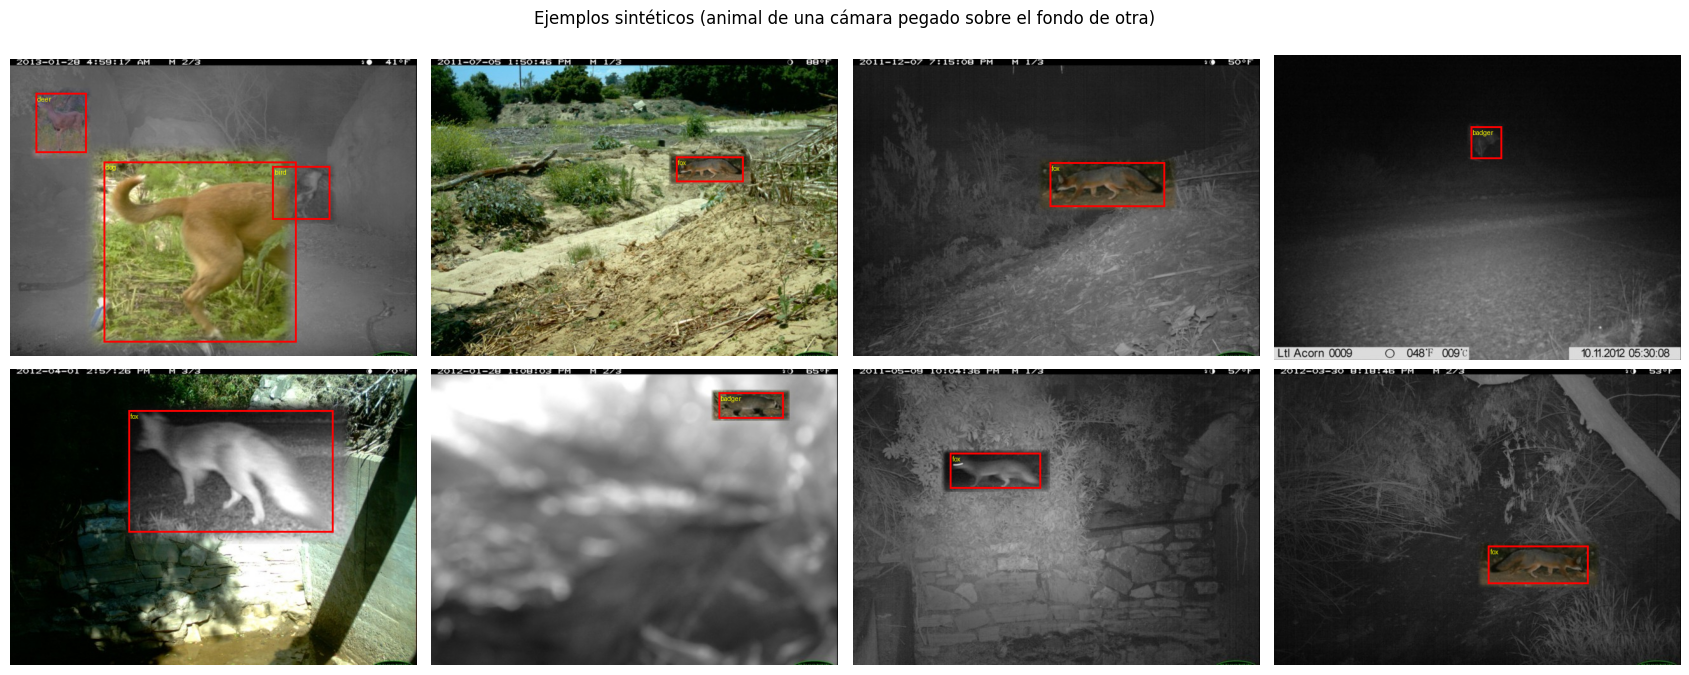

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(17, 7))
for a, name in zip(axs.ravel(), made[:8]):
    im = Image.open(SY_IMG / f'{name}.jpg').convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
    for l in (SY_LAB / f'{name}.txt').read_text().splitlines():
        c, xc, yc, w, h = l.split(); xc, yc, w, h = map(float, (xc, yc, w, h))
        d.rectangle([(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H], outline='red', width=3)
        d.text(((xc - w/2) * W + 3, (yc - h/2) * H + 3), U.CLASSES[int(c)], fill='yellow')
    a.imshow(im); a.axis('off')
plt.suptitle('Ejemplos sintéticos (animal de una cámara pegado sobre el fondo de otra)'); plt.tight_layout(); plt.show()

## 3. Entrenamiento de los brazos
Mismas épocas, modelo y semilla que el baseline. Los resultados quedan en `cct_yolo/runs/<brazo>`; si un brazo ya fue entrenado, se omite.

In [ ]:
ARMS = {
    'strong_aug': dict(train=['images/train_rfs'], aug=STRONG_AUG),
    'bgswap': dict(train=['images/train_rfs', 'images/train_synth'], aug=STRONG_AUG),
}

def train_arm(name, train, aug):
    best = U.DRIVE_DIR / 'runs' / name / 'weights' / 'best.pt'
    if best.exists():
        print(f'[{name}] ya entrenado, se reutiliza'); return best
    yml = U.make_yaml(f'train_{name}', train=train, val='images/cis_val')
    YOLO(MODEL).train(data=str(yml), epochs=EPOCHS, imgsz=U.IMGSZ, batch=BATCH, patience=PATIENCE,
                      project=str(U.DRIVE_DIR / 'runs'), name=name, exist_ok=True, seed=U.SEED,
                      cos_lr=True, close_mosaic=5, workers=4, amp=True, plots=True, **aug)
    return best

for arm in RUN_ARMS:
    train_arm(arm, **ARMS[arm])

[bgswap] ya entrenado, se reutiliza


In [ ]:
# (OPCIONAL, requiere un entrenamiento extra) Brazo 'no_rfs': igual al baseline pero SIN Repeat Factor Sampling.
# Sirve para el Entregable 2: mide directamente cuánto ayuda RFS a las especies con pocos ejemplos.
# Ejecutar ANTES de la sección 4 si se quiere que entre en las tablas comparativas.
RUN_NO_RFS = False
if RUN_NO_RFS:
    ARMS['no_rfs'] = dict(train=['images/train'], aug=base['config']['aug'])
    train_arm('no_rfs', **ARMS['no_rfs'])

## 4. Evaluación comparativa cis vs. trans

In [ ]:
arms_done = [BASELINE_RUN] + [a for a in ARMS if (U.DRIVE_DIR / 'runs' / a / 'weights' / 'best.pt').exists()]
rows, preds_all, per_loc = [], {}, []
for arm in arms_done:
    w = U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt'
    for s in ['cis_val', 'trans_val']:
        r = U.eval_detector(w, s, arm)
        p = U.predict_split(w, s, arm, conf=0.05, force=(arm != BASELINE_RUN))
        preds_all[(arm, s)] = p
        Ms = meta[meta.split == s]
        il = U.image_level_metrics(Ms, p, THR)
        rows.append(dict(brazo=arm, split=s, mAP50=r['map50'], mAP50_95=r['map50_95'], P=r['precision'], R=r['recall'],
                         F1_imagen=il['f1'], falsas_alarmas_vacias=il['empty_false_alarm']))
        lm = U.per_location_image_metrics(Ms, p, THR); lm['brazo'] = arm; lm['split'] = s
        per_loc.append(lm)
R = pd.DataFrame(rows)
print(R.round(3).to_string(index=False))

piv = R.pivot(index='brazo', columns='split', values=['mAP50', 'mAP50_95', 'F1_imagen'])
gap = pd.DataFrame({m: piv[m]['cis_val'] - piv[m]['trans_val'] for m in ['mAP50', 'mAP50_95', 'F1_imagen']})
gap.columns = [f'brecha_{c}' for c in gap.columns]
print('\nBrecha de generalización (cis − trans); menor es mejor:')
print(gap.round(3).to_string())
(U.DRIVE_DIR / 'summaries').mkdir(exist_ok=True)
R.to_csv(U.DRIVE_DIR / 'summaries' / 'exp_generalizacion.csv', index=False)

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 24.6±10.4 MB/s, size: 72.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/cct/labels/cis_val... 3875 images, 309 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3875/3875 467.8it/s 8.3s
val: New cache created: /content/cct/labels/cis_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 122/122 2.6it/s 47.3s
                   all       3875       3747      0.919      0.806      0.927      0.638
Speed: 0.9ms preprocess, 8.3ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/drive/MyDrive/Dfoto/eval/baseline_cis_val
Ultralytics 8.4.184 🚀 Python-3.13.16 torch

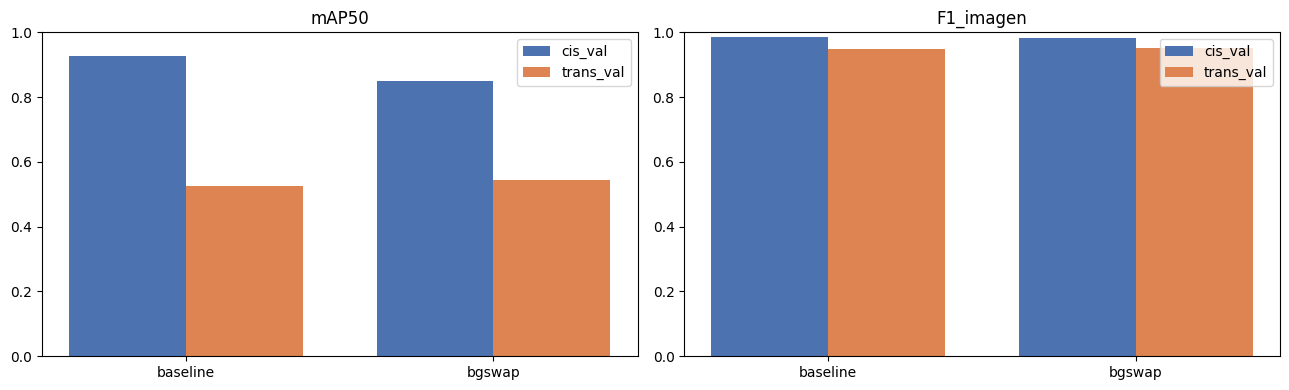

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(arms_done)); w = 0.38
for a, met in zip(ax, ['mAP50', 'F1_imagen']):
    a.bar(x - w/2, [R[(R.brazo == b) & (R.split == 'cis_val')][met].iloc[0] for b in arms_done], w, label='cis_val', color='#4C72B0')
    a.bar(x + w/2, [R[(R.brazo == b) & (R.split == 'trans_val')][met].iloc[0] for b in arms_done], w, label='trans_val', color='#DD8452')
    a.set_xticks(x); a.set_xticklabels(arms_done); a.set_title(met); a.legend(); a.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 4.1 Entregable 3 · Brecha cis vs. trans con incertidumbre (por cámara)

Partición oficial: **cámaras vistas** = `eccv_train` (evaluadas en `cis_val`, secuencias reservadas) frente a **cámaras completamente nuevas** = `eccv_val` (`trans_val`).

La tabla de la sección 4 da el mAP *agrupando todas las imágenes*. Como la unidad real de generalización es la **cámara** (no la imagen), aquí se calcula el mAP@0.5 y mAP@0.5:0.95 **dentro de cada cámara** y se reporta:
- media por cámara en cada grupo y **brecha = cis − trans**,
- **IC 95 %** de la brecha por *bootstrap sobre cámaras* (se remuestrean las cámaras de cada grupo),
- brecha relativa (% del valor en cis).

> El mAP por cámara promedia solo sobre las especies presentes en esa cámara, por lo que es ruidoso cámara a cámara; lo informativo es la distribución y el promedio.

mAP por cámara (cis_val):   0%|          | 0/10 [00:00<?, ?it/s]

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2154.3±363.3 MB/s, size: 105.7 KB)
val: Scanning /content/cct/labels/cis_val... 131 images, 29 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131 2.3Kit/s 0.1s
val: New cache created: /content/cct/labels/cis_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.4it/s 2.0s
                   all        131        104      0.838      0.643      0.734      0.416
Speed: 0.8ms preprocess, 9.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1193.0±753.8 MB/s, size: 101.4 KB)
val: Scanning /conte

mAP por cámara (trans_val):   0%|          | 0/10 [00:00<?, ?it/s]

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1454.9±818.1 MB/s, size: 61.7 KB)
val: Scanning /content/cct/labels/trans_val... 1000 images, 22 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 2.1Kit/s 0.5s
val: New cache created: /content/cct/labels/trans_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.5it/s 12.6s
                   all       1000        998      0.848      0.556      0.689       0.51
Speed: 0.7ms preprocess, 9.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1711.0±971.2 MB/s, size: 81.1 KB)
val: Scannin

mAP por cámara (cis_val):   0%|          | 0/10 [00:00<?, ?it/s]

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1217.8±516.3 MB/s, size: 76.8 KB)
val: Scanning /content/cct/labels/cis_val... 131 images, 29 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131 2.0Kit/s 0.1s
val: New cache created: /content/cct/labels/cis_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.5it/s 2.0s
                   all        131        104      0.637      0.852      0.776      0.437
Speed: 0.8ms preprocess, 9.4ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1452.0±578.6 MB/s, size: 72.6 KB)
val: Scanning /content

mAP por cámara (trans_val):   0%|          | 0/10 [00:00<?, ?it/s]

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1123.7±126.3 MB/s, size: 51.2 KB)
val: Scanning /content/cct/labels/trans_val... 1000 images, 22 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 2.1Kit/s 0.5s
val: New cache created: /content/cct/labels/trans_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.5it/s 12.6s
                   all       1000        998      0.835      0.656      0.726      0.542
Speed: 0.7ms preprocess, 9.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1908.2±806.9 MB/s, size: 82.2 KB)
val: Scannin

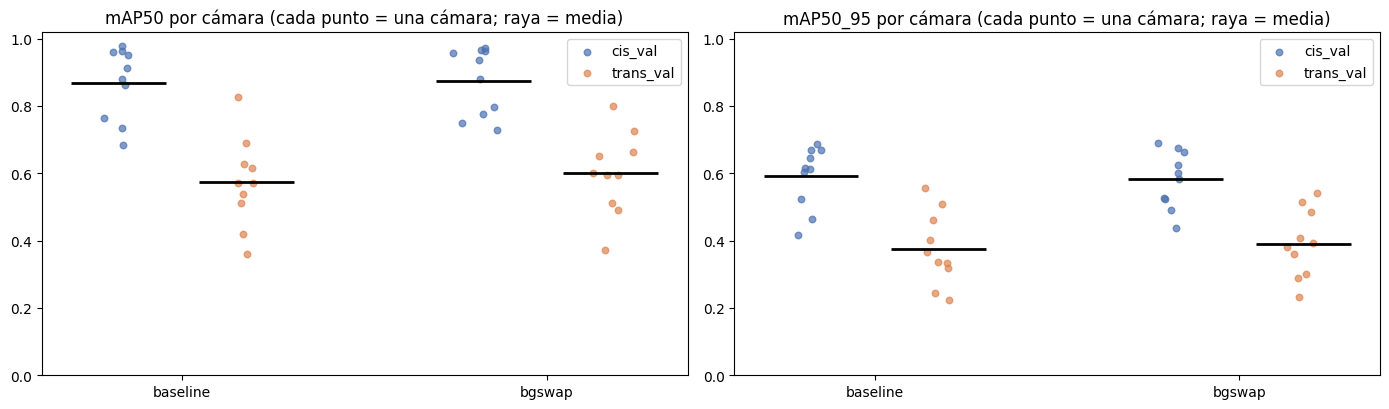

Cámaras de trans_val con peor mAP50 (baseline):
location  n_img  n_inst  mAP50  mAP50_95
      40    890     836  0.359     0.224
      78   1001     910  0.419     0.243
     130   1000     929  0.513     0.320
      46   1000     874  0.538     0.336
     105   1000     997  0.571     0.333


In [ ]:
from tqdm.auto import tqdm
PER_CAM_FILE = U.DRIVE_DIR / 'summaries' / 'exp_generalizacion_por_camara.csv'
FORCE_RECOMPUTE = False          # True si reentrenaste algún brazo

def eval_by_location(weights, split):
    """mAP@0.5 y mAP@0.5:0.95 de Ultralytics calculados por separado en cada cámara de un split."""
    m = YOLO(str(weights))
    Ms = meta[meta.split == split]
    (U.LOCAL / 'lists').mkdir(exist_ok=True)
    out = []
    for loc, g in tqdm(list(Ms.groupby('location')), desc=f'mAP por cámara ({split})'):
        row = dict(location=str(loc), n_img=len(g), n_inst=int(g['n_boxes'].sum()), mAP50=np.nan, mAP50_95=np.nan)
        if row['n_inst'] > 0:
            name = f'{split}_loc{loc}'
            (U.LOCAL / 'lists' / f'{name}.txt').write_text('\n'.join(str(U.LOCAL / 'images' / split / f) for f in g['file']))
            yml = U.make_yaml(f'bycam_{name}', 'images/train', f'lists/{name}.txt')
            r = m.val(data=str(yml), imgsz=U.IMGSZ, batch=BATCH, conf=0.001, iou=0.6, plots=False, verbose=False,
                      project=str(U.LOCAL / 'tmp_eval'), name='bycam', exist_ok=True)
            row.update(mAP50=float(r.box.map50), mAP50_95=float(r.box.map))
        out.append(row)
    return pd.DataFrame(out)

PCAM = pd.read_csv(PER_CAM_FILE, dtype={'location': str}) if (PER_CAM_FILE.exists() and not FORCE_RECOMPUTE) else pd.DataFrame()
for arm in arms_done:
    if len(PCAM) and (PCAM['arm'] == arm).any():
        continue
    w = U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt'
    for s in ['cis_val', 'trans_val']:
        d = eval_by_location(w, s); d['arm'] = arm; d['split'] = s
        PCAM = pd.concat([PCAM, d], ignore_index=True)
PCAM.to_csv(PER_CAM_FILE, index=False)

def boot_gap(a, b, n=5000, seed=0):
    """IC95% de mean(a) - mean(b) remuestreando los elementos (cámaras) de cada grupo."""
    r = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a) < 2 or len(b) < 2:
        return np.nan, np.nan
    d = [r.choice(a, len(a)).mean() - r.choice(b, len(b)).mean() for _ in range(n)]
    return tuple(np.percentile(d, [2.5, 97.5]))

rows = []
for arm in arms_done:
    ci_, tr_ = (PCAM[(PCAM.arm == arm) & (PCAM.split == s)] for s in ['cis_val', 'trans_val'])
    for met in ['mAP50', 'mAP50_95']:
        a, b = ci_[met].dropna().values, tr_[met].dropna().values
        lo, hi = boot_gap(a, b)
        rows.append(dict(brazo=arm, metrica=met, cis_media_cams=a.mean(), trans_media_cams=b.mean(), brecha=a.mean() - b.mean(),
                         IC95_inf=lo, IC95_sup=hi, brecha_relativa_pct=100 * (a.mean() - b.mean()) / a.mean(),
                         n_cams_cis=len(a), n_cams_trans=len(b)))
GAP = pd.DataFrame(rows)
print('BRECHA DE GENERALIZACIÓN (cámaras vistas − cámaras nuevas), media por cámara')
print(GAP.round(3).to_string(index=False))
print('\nSi el IC95% de la brecha excluye 0, hay evidencia de que el rendimiento cae en cámaras nuevas. '
      'Comparar la brecha entre brazos indica si una técnica la reduce.')
GAP.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_brecha_cis_trans.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); jr = np.random.default_rng(1)
for a_, met in zip(ax, ['mAP50', 'mAP50_95']):
    for i, arm in enumerate(arms_done):
        for k, (s, col) in enumerate([('cis_val', '#4C72B0'), ('trans_val', '#DD8452')]):
            v = PCAM[(PCAM.arm == arm) & (PCAM.split == s)][met].dropna().values
            xx = i + (k - .5) * .35
            a_.scatter(xx + jr.normal(0, .03, len(v)), v, s=22, alpha=.7, color=col, label=s if i == 0 else None)
            a_.hlines(v.mean(), xx - .13, xx + .13, color='k', lw=2)
    a_.set_xticks(range(len(arms_done))); a_.set_xticklabels(arms_done); a_.set_ylim(0, 1.02)
    a_.set_title(f'{met} por cámara (cada punto = una cámara; raya = media)'); a_.legend()
plt.tight_layout(); plt.show()
print('Cámaras de trans_val con peor mAP50 (baseline):')
print(PCAM[(PCAM.arm == BASELINE_RUN) & (PCAM.split == 'trans_val')].sort_values('mAP50')[['location', 'n_img', 'n_inst', 'mAP50', 'mAP50_95']].head(5).round(3).to_string(index=False))

## 5. Variabilidad por cámara nueva
El "n" real de la generalización es el **número de cámaras** (≈10), no el de imágenes. Se muestra F1 por cámara y la tasa de falsas alarmas sobre vacías.

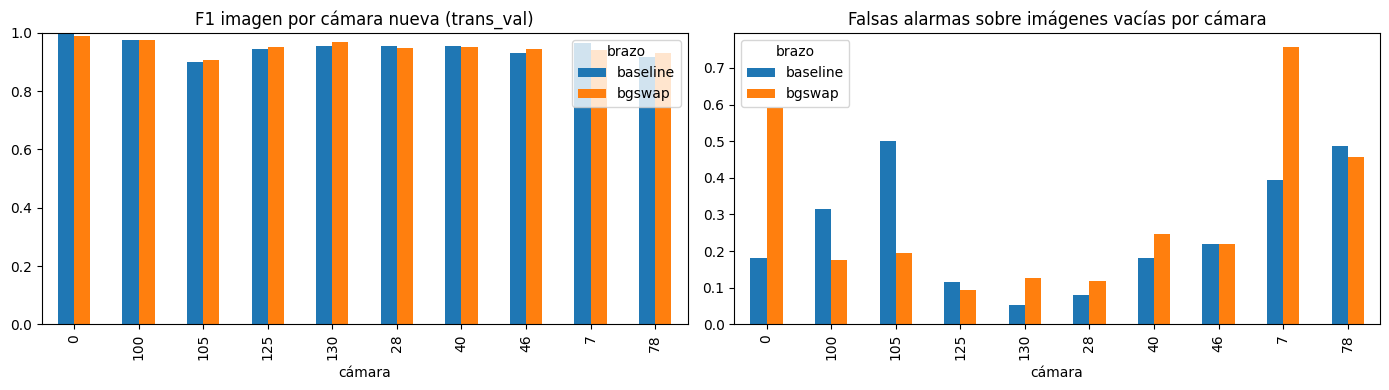

Cámaras con peor F1 (baseline):
location
105    0.899
78     0.917
46     0.932
125    0.943
28     0.953


In [ ]:
PL = pd.concat(per_loc)
t = PL[PL.split == 'trans_val'].pivot(index='location', columns='brazo', values='f1')
fa = PL[PL.split == 'trans_val'].pivot(index='location', columns='brazo', values='empty_false_alarm')
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
t.plot.bar(ax=ax[0]); ax[0].set_title('F1 imagen por cámara nueva (trans_val)'); ax[0].set_xlabel('cámara'); ax[0].set_ylim(0, 1)
fa.plot.bar(ax=ax[1]); ax[1].set_title('Falsas alarmas sobre imágenes vacías por cámara'); ax[1].set_xlabel('cámara')
plt.tight_layout(); plt.show()
print('Cámaras con peor F1 (baseline):')
print(t[BASELINE_RUN].sort_values().head(5).round(3).to_string())

In [ ]:
# Comparación pareada por cámara (bootstrap sobre cámaras) frente al baseline
rng = np.random.default_rng(0)
for arm in [a for a in arms_done if a != BASELINE_RUN]:
    d = (t[arm] - t[BASELINE_RUN]).dropna().values
    boots = [rng.choice(d, size=len(d), replace=True).mean() for _ in range(5000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f'{arm} − baseline | ΔF1 medio por cámara = {d.mean():+.3f}  IC95% bootstrap [{lo:+.3f}, {hi:+.3f}]  (n={len(d)} cámaras)')
print('\nSi el IC incluye 0, no hay evidencia sólida de mejora con una sola semilla y ~10 cámaras. Para concluir, repetir con varias semillas.')

bgswap − baseline | ΔF1 medio por cámara = +0.001  IC95% bootstrap [-0.006, +0.008]  (n=10 cámaras)

Si el IC incluye 0, no hay evidencia sólida de mejora con una sola semilla y ~10 cámaras. Para concluir, repetir con varias semillas.


## 6. Por especie: ¿quién cae más al cambiar de cámara?

In [ ]:
pcs = {}
for arm in arms_done:
    w = U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt'
    pcs[arm] = U.eval_detector(w, 'trans_val', arm)['per_class']
tab = pd.DataFrame({arm: {c: v['ap50'] for c, v in pc.items()} for arm, pc in pcs.items()})
tab['inst_trans'] = pd.Series(U.count_instances('trans_val'))
tab['inst_train'] = pd.Series(U.count_instances('train'))
print(tab.sort_values('inst_train', ascending=False).round(3).to_string())
tab.to_csv(U.DRIVE_DIR / 'summaries' / 'exp_generalizacion_por_especie_trans.csv')

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1428.8±855.6 MB/s, size: 60.5 KB)
val: Scanning /content/cct/labels/trans_val... 9895 images, 881 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9895/9895 2.1Kit/s 4.7s
val: New cache created: /content/cct/labels/trans_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 2.4it/s 2:11
                   all       9895       9356      0.597      0.519      0.526      0.362
Speed: 0.7ms preprocess, 9.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/drive/MyDrive/Dfoto/eval/baseline_trans_val
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅

## 6.1 Entregable 3 · Brecha por especie y confusión especie–cámara

Si una especie aparece en **una sola cámara** (o casi), el modelo puede aprender «el fondo de esa cámara» en vez del animal. Predicción: las especies **concentradas** en pocas cámaras de entrenamiento deberían perder más AP al pasar a cámaras nuevas.

Se mide para cada especie: nº de cámaras de train donde aparece, **proporción de sus imágenes en su cámara principal**, y la caída de AP (cis − trans).

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1900.1±731.7 MB/s, size: 89.6 KB)
val: Scanning /content/cct/labels/cis_val... 3875 images, 309 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3875/3875 2.1Kit/s 1.9s
val: New cache created: /content/cct/labels/cis_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 122/122 2.3it/s 52.7s
                   all       3875       3747      0.847      0.823      0.849      0.588
Speed: 0.9ms preprocess, 9.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/drive/MyDrive/Dfoto/eval/bgswap_cis_val
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping:

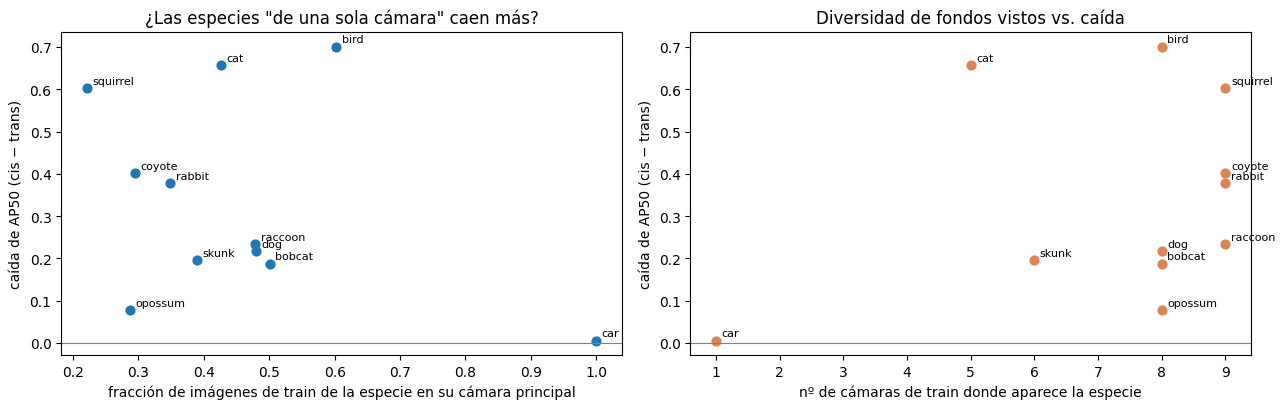

Con ~15 especies y pocas instancias en trans esta correlación es solo indicativa (se reporta con su p-valor).


In [ ]:
from scipy.stats import spearmanr
MIN_INST_EVAL = 10         # instancias mínimas en cis y en trans para incluir la especie en la correlación
COMMON_MIN, RARE_MAX = 1000, 100

def get_eval(arm, split):
    if arm == BASELINE_RUN and split in base['metrics']:       # ya calculado en el notebook 02
        return base['metrics'][split]
    return U.eval_detector(U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt', split, arm)

EV = {(arm, s): get_eval(arm, s) for arm in arms_done for s in ['cis_val', 'trans_val']}
inst_tr, inst_ci, inst_te = (U.count_instances(s) for s in ['train', 'cis_val', 'trans_val'])

cnt = {}
for r in meta[meta.split == 'train'].itertuples():
    for c in set(r.species.split('|')):
        if c:
            cnt.setdefault(c, Counter())[r.location] += 1
conc = pd.DataFrame({c: dict(camaras_train=len(v), share_camara_principal=max(v.values()) / sum(v.values()))
                     for c, v in cnt.items()}).T

SG = []
for arm in arms_done:
    for c in U.CLASSES:
        a, b = EV[(arm, 'cis_val')]['per_class'].get(c), EV[(arm, 'trans_val')]['per_class'].get(c)
        SG.append(dict(brazo=arm, especie=c, inst_train=inst_tr.get(c, 0), inst_cis=inst_ci.get(c, 0), inst_trans=inst_te.get(c, 0),
                       AP50_cis=a['ap50'] if a else np.nan, AP50_trans=b['ap50'] if b else np.nan,
                       AP50_95_cis=a['ap'] if a else np.nan, AP50_95_trans=b['ap'] if b else np.nan))
SG = pd.DataFrame(SG).merge(conc, left_on='especie', right_index=True, how='left')
SG['brecha_AP50'] = SG['AP50_cis'] - SG['AP50_trans']
SG['brecha_AP50_95'] = SG['AP50_95_cis'] - SG['AP50_95_trans']
SG['grupo'] = SG['inst_train'].map(lambda n: 'sin ejemplos' if n == 0 else ('común' if n >= COMMON_MIN else ('rara' if n < RARE_MAX else 'intermedia')))
SG.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_brecha_por_especie.csv', index=False)

b0 = SG[SG.brazo == BASELINE_RUN].sort_values('inst_train', ascending=False)
print(f'BRECHA POR ESPECIE ({BASELINE_RUN})')
print(b0[['especie', 'grupo', 'inst_train', 'camaras_train', 'share_camara_principal', 'inst_cis', 'inst_trans',
          'AP50_cis', 'AP50_trans', 'brecha_AP50', 'brecha_AP50_95']].round(3).to_string(index=False))

print('\nBrecha media por grupo de frecuencia (solo especies con AP definido en cis y trans):')
okm = SG[(SG.inst_cis >= 1) & (SG.inst_trans >= 1)]
print(okm.groupby(['brazo', 'grupo'])[['AP50_cis', 'AP50_trans', 'brecha_AP50', 'brecha_AP50_95']].mean().round(3).to_string())

print('\nCorrelación de Spearman entre la concentración en una cámara y la caída de AP50 (cis − trans):')
for arm in arms_done:
    d = SG[(SG.brazo == arm) & (SG.inst_cis >= MIN_INST_EVAL) & (SG.inst_trans >= MIN_INST_EVAL)].dropna(subset=['brecha_AP50', 'share_camara_principal'])
    if len(d) >= 4:
        rho, pv = spearmanr(d['share_camara_principal'], d['brecha_AP50'])
        rho2, pv2 = spearmanr(d['camaras_train'], d['brecha_AP50'])
        print(f'  {arm:<10} ρ(share cámara principal, brecha) = {rho:+.2f} (p={pv:.3f}) | ρ(nº cámaras train, brecha) = {rho2:+.2f} (p={pv2:.3f}) | n={len(d)} especies')
    else:
        print(f'  {arm:<10} muy pocas especies con ≥{MIN_INST_EVAL} instancias en cis y trans (n={len(d)}): no se calcula.')

d = b0[(b0.inst_cis >= MIN_INST_EVAL) & (b0.inst_trans >= MIN_INST_EVAL)].dropna(subset=['brecha_AP50'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(d['share_camara_principal'], d['brecha_AP50'], s=40)
for r in d.itertuples():
    ax[0].annotate(r.especie, (r.share_camara_principal, r.brecha_AP50), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax[0].axhline(0, c='gray', lw=.8); ax[0].set_xlabel('fracción de imágenes de train de la especie en su cámara principal')
ax[0].set_ylabel('caída de AP50 (cis − trans)'); ax[0].set_title('¿Las especies "de una sola cámara" caen más?')
ax[1].scatter(d['camaras_train'], d['brecha_AP50'], s=40, c='#DD8452')
for r in d.itertuples():
    ax[1].annotate(r.especie, (r.camaras_train, r.brecha_AP50), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax[1].axhline(0, c='gray', lw=.8); ax[1].set_xlabel('nº de cámaras de train donde aparece la especie')
ax[1].set_ylabel('caída de AP50 (cis − trans)'); ax[1].set_title('Diversidad de fondos vistos vs. caída')
plt.tight_layout(); plt.show()
print('Con ~15 especies y pocas instancias en trans esta correlación es solo indicativa (se reporta con su p-valor).')

## 6.2 Entregable 3 · ¿Mira el animal o mira el fondo? Grad-CAM sobre el backbone

**Método.** Grad-CAM (Selvaraju et al.) aplicado a la **última capa del backbone** de YOLO (la que precede al primer `Upsample`: `SPPF` en YOLOv8, `C2PSA` en YOLO11; stride 32). El escalar que se deriva es la **puntuación de clase más alta de toda la imagen** (la detección que el modelo "elegiría"). El mapa resultante indica qué regiones de la imagen empujan esa puntuación.

**Métricas cuantitativas** (en imágenes con animal y su caja real):
- **Atención dentro de la caja** = fracción de la energía del mapa que cae sobre el animal. Un mapa uniforme daría exactamente el área relativa de la caja.
- **Exceso de atención** = atención dentro de la caja − área relativa de la caja (> 0: mira al animal; ≈ 0: reparte la atención como si no distinguiera; < 0: mira el fondo).
- **Pointing game** = % de imágenes cuyo máximo del mapa cae dentro de la caja.
- Se filtran cajas con área relativa < 0.1 % o > 50 % para no inflar/aplanar la métrica.

La comparación relevante es **cis_val vs. trans_val** (¿cambia el foco al pasar a cámaras nuevas?) y **baseline vs. brazos con aumento/intercambio de fondo**.

> Limitaciones: Grad-CAM a stride 32 es grueso (≈ 20×15 celdas) y es una explicación *correlacional*; por eso se complementa con las pruebas contrafactuales de la sección 6.3, que sí son causales.

In [ ]:
import cv2
import torch.nn.functional as F

def letterbox_tensor(im, size=U.IMGSZ, stride=32):
    """Redimensiona al estilo Ultralytics (lado mayor = size, relleno gris hasta múltiplo de stride)."""
    W, H = im.size
    r = min(size / W, size / H)
    nw, nh = int(round(W * r)), int(round(H * r))
    Wc, Hc = int(math.ceil(nw / stride) * stride), int(math.ceil(nh / stride) * stride)
    canvas = Image.new('RGB', (Wc, Hc), (114, 114, 114))
    left, top = (Wc - nw) // 2, (Hc - nh) // 2
    canvas.paste(im.resize((nw, nh), Image.BILINEAR), (left, top))
    x = torch.from_numpy(np.asarray(canvas, dtype=np.float32) / 255.).permute(2, 0, 1)[None]
    return x, (left, top, nw, nh)

class GradCAMYolo:
    """Grad-CAM sobre la última capa del backbone de un detector Ultralytics (YOLOv8 / YOLO11)."""
    def __init__(self, weights, layer_idx=None):
        self.dev = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.model = YOLO(str(weights)).model.to(self.dev).float().eval()
        for p in self.model.parameters():
            p.requires_grad_(True)
        seq = self.model.model
        if layer_idx is None:
            ups = [i for i, m in enumerate(seq) if m.__class__.__name__ == 'Upsample']
            layer_idx = ups[0] - 1 if ups else len(seq) - 2
        self.layer_idx, self.layer_name, self._act = layer_idx, seq[layer_idx].__class__.__name__, None
        self._h = seq[layer_idx].register_forward_hook(lambda m, i, o: setattr(self, '_act', o))

    def close(self):
        self._h.remove()

    def __call__(self, im, cls_id=None):
        """Devuelve (mapa 0-1 del tamaño de la imagen original, puntuación objetivo, clase de la detección top)."""
        x, (left, top, nw, nh) = letterbox_tensor(im)
        x = x.to(self.dev).requires_grad_(True)
        with torch.enable_grad():
            out = self.model(x)
            y = out[0] if isinstance(out, (list, tuple)) else out
            if not (torch.is_tensor(y) and y.ndim == 3 and y.shape[1] == 4 + len(U.CLASSES)):
                raise RuntimeError('Salida del modelo no reconocida; usa yolov8/yolo11 (cabeza Detect clásica) para Grad-CAM.')
            sc = y[0, 4:, :]                                   # [clases, anclas] (ya con sigmoide)
            score = sc.max() if cls_id is None else sc[cls_id].max()
            act = self._act
            grad = torch.autograd.grad(score, act)[0]
        wts = grad.mean(dim=(2, 3), keepdim=True)              # pesos = gradiente medio por canal
        cam = F.relu((wts * act.detach()).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode='bilinear', align_corners=False)[0, 0]
        cam = cam[top:top + nh, left:left + nw].cpu().numpy()  # quita el relleno
        cam = cv2.resize(cam, im.size, interpolation=cv2.INTER_LINEAR)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-9)
        return cam, float(score.item()), int(sc.max(1).values.argmax())

def read_boxes(split, fname):
    """Cajas reales normalizadas (x1, y1, x2, y2, clase) de una imagen."""
    out = []
    for l in (U.LOCAL / 'labels' / split / (Path(fname).stem + '.txt')).read_text().splitlines():
        if l.strip():
            c, xc, yc, w, h = l.split(); xc, yc, w, h = map(float, (xc, yc, w, h))
            out.append((xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2, int(c)))
    return out

def cam_metrics(cam, boxes):
    H, W = cam.shape
    mask = np.zeros((H, W), bool)
    for x1, y1, x2, y2, _ in boxes:
        mask[int(y1 * H):int(math.ceil(y2 * H)), int(x1 * W):int(math.ceil(x2 * W))] = True
    area = float(mask.mean())
    tot = float(cam.sum())
    if tot < 1e-9 or area == 0:
        return None
    e_in = float(cam[mask].sum() / tot)
    hit = bool(mask[np.unravel_index(cam.argmax(), cam.shape)])
    return dict(area=area, energy_in=e_in, exceso=e_in - area, ratio=e_in / area, hit=float(hit))

def sample_with_animals(split, n_per_cam, seed=0):
    Ms = meta[(meta.split == split) & (meta.n_boxes > 0)]
    return pd.concat([g.sample(min(len(g), n_per_cam), random_state=seed) for _, g in Ms.groupby('location')])

# prueba rápida del motor sobre una imagen
_gc = GradCAMYolo(U.DRIVE_DIR / 'runs' / BASELINE_RUN / 'weights' / 'best.pt')
_r = sample_with_animals('trans_val', 1).iloc[0]
_im = Image.open(U.LOCAL / 'images' / 'trans_val' / _r.file).convert('RGB')
_cam, _sc, _c = _gc(_im)
print(f'Capa objetivo: modelo[{_gc.layer_idx}] = {_gc.layer_name} | mapa {_cam.shape} | puntuación {_sc:.3f} | clase top: {U.CLASSES[_c]} | métricas: {cam_metrics(_cam, read_boxes("trans_val", _r.file))}')
_gc.close()

Capa objetivo: modelo[9] = SPPF | mapa (480, 640) | puntuación 0.875 | clase top: bobcat | métricas: {'area': 0.038912760416666664, 'energy_in': 0.25062447786331177, 'exceso': 0.2117117174466451, 'ratio': 6.440675890882498, 'hit': 1.0}


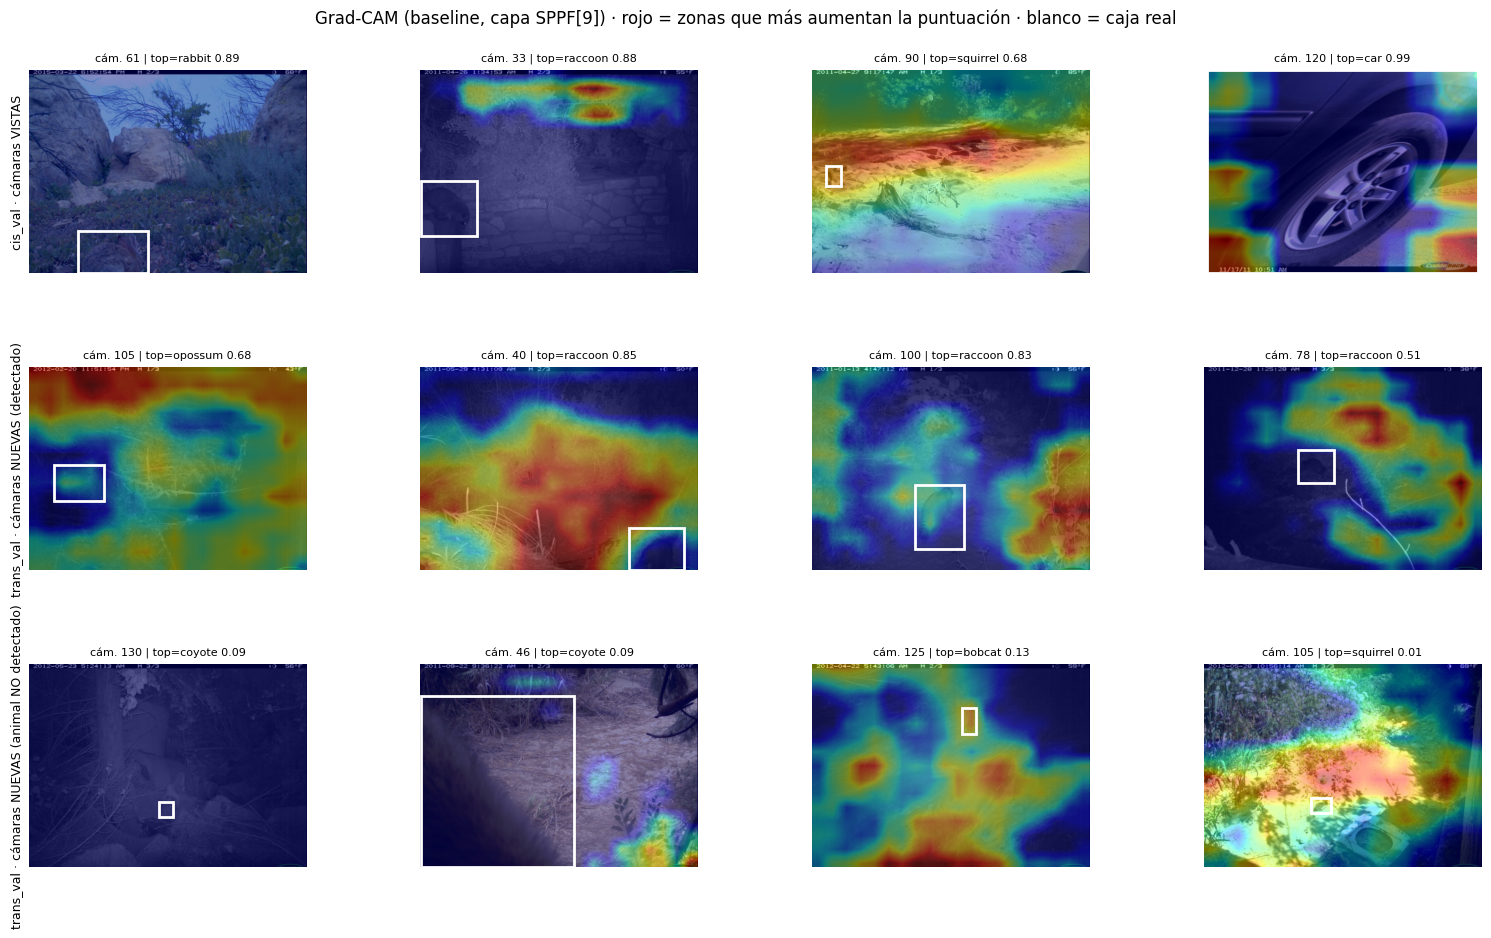

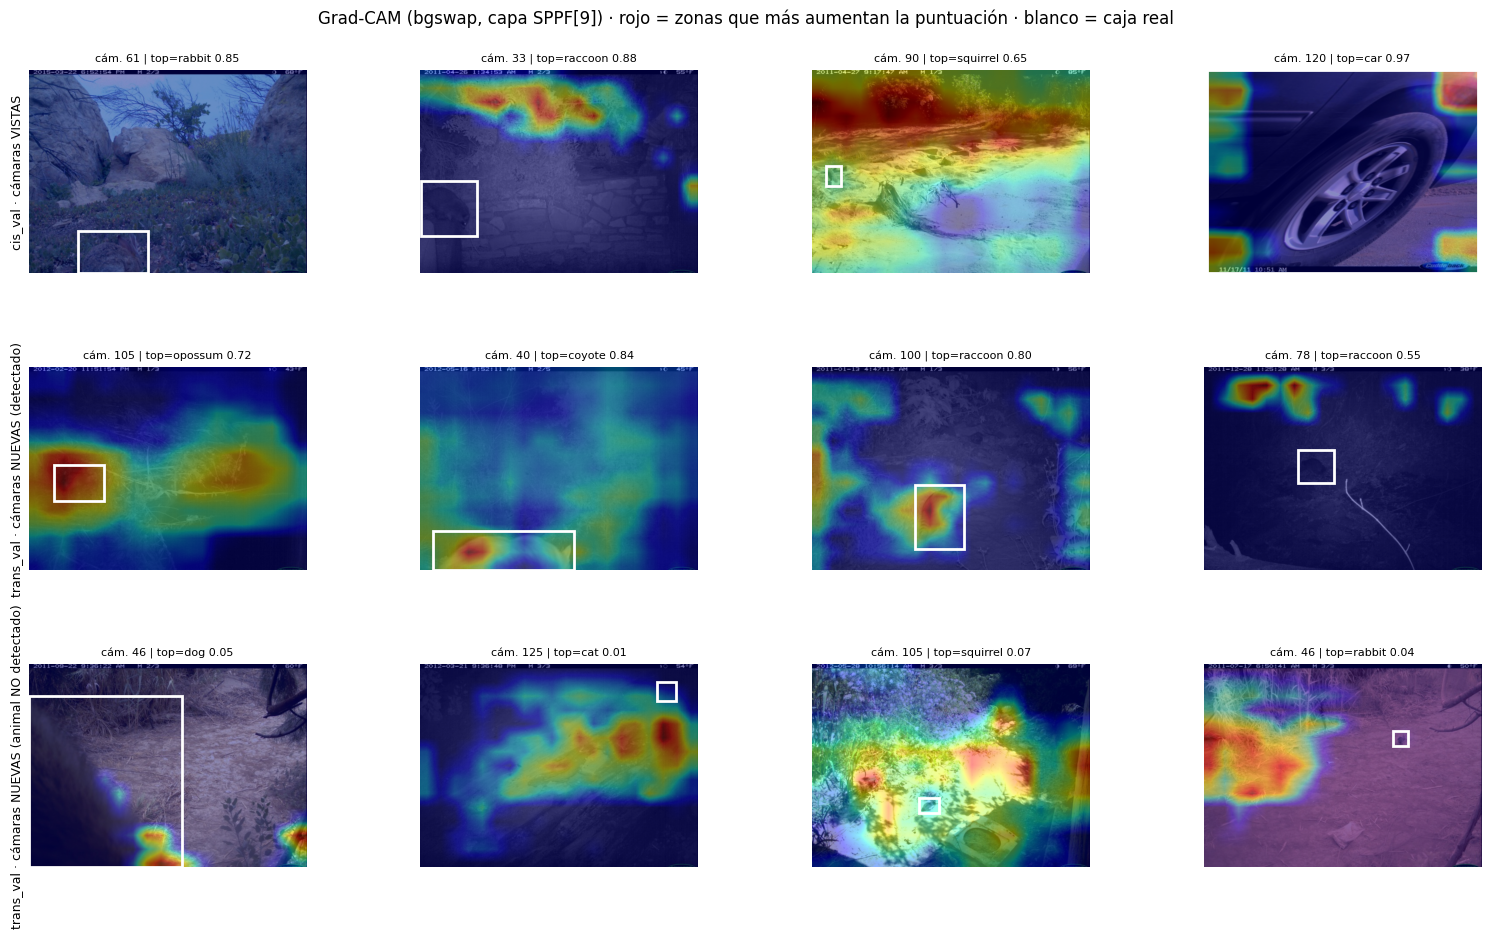

In [ ]:
def draw_cam(a, im, cam, boxes, title):
    a.imshow(im); a.imshow(cam, cmap='jet', alpha=0.45)
    W, H = im.size
    for x1, y1, x2, y2, _ in boxes:
        a.add_patch(plt.Rectangle((x1 * W, y1 * H), (x2 - x1) * W, (y2 - y1) * H, fill=False, ec='white', lw=2))
    a.set_title(title, fontsize=8); a.axis('off')

def cam_panels(arm, n=4, seed=3):
    gc = GradCAMYolo(U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt')
    Pt = preds_all[(arm, 'trans_val')]
    detected = set(Pt[Pt.conf >= THR].file)
    groups = []
    g = sample_with_animals('cis_val', 6, seed=seed).sample(n, random_state=seed); groups.append(('cis_val · cámaras VISTAS', 'cis_val', g))
    S = sample_with_animals('trans_val', 6, seed=seed)
    hit_ = S[S.file.isin(detected)]
    if len(hit_):
        groups.append(('trans_val · cámaras NUEVAS (detectado)', 'trans_val', hit_.sample(min(n, len(hit_)), random_state=seed)))
    miss = S[~S.file.isin(detected)]
    if len(miss):
        groups.append(('trans_val · cámaras NUEVAS (animal NO detectado)', 'trans_val', miss.sample(min(n, len(miss)), random_state=seed)))
    fig, axs = plt.subplots(len(groups), n, figsize=(4 * n, 3.1 * len(groups)), squeeze=False)
    for row, (name, split, df) in enumerate(groups):
        for k in range(n):
            axs[row, k].axis('off')
        axs[row, 0].text(-0.02, 0.5, name, transform=axs[row, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9)
        for k, r in enumerate(df.itertuples()):
            im = Image.open(U.LOCAL / 'images' / split / r.file).convert('RGB')
            cam, sc, c = gc(im)
            draw_cam(axs[row, k], im, cam, read_boxes(split, r.file), f'cám. {r.location} | top={U.CLASSES[c]} {sc:.2f}')
    plt.suptitle(f'Grad-CAM ({arm}, capa {gc.layer_name}[{gc.layer_idx}]) · rojo = zonas que más aumentan la puntuación · blanco = caja real', y=1.0)
    plt.tight_layout(); plt.savefig(U.DRIVE_DIR / 'figs' / f'gradcam_{arm}.png', dpi=140); plt.show()
    gc.close()

(U.DRIVE_DIR / 'figs').mkdir(exist_ok=True)
for arm in arms_done:
    cam_panels(arm)

Grad-CAM baseline/cis_val:   0%|          | 0/120 [00:00<?, ?it/s]

Grad-CAM baseline/trans_val:   0%|          | 0/120 [00:00<?, ?it/s]

Grad-CAM bgswap/cis_val:   0%|          | 0/120 [00:00<?, ?it/s]

Grad-CAM bgswap/trans_val:   0%|          | 0/120 [00:00<?, ?it/s]

GRAD-CAM: ¿se concentra la atención en el animal? (media por cámara; n real = nº de cámaras)
   brazo                            metrica   cis  trans  dif_cis_menos_trans  IC95_inf  IC95_sup  n_cams_cis  n_cams_trans
baseline         atención dentro de la caja 0.082  0.051                0.031    -0.029     0.112          10            10
baseline exceso de atención (dentro − área) 0.035  0.013                0.022    -0.022     0.093          10            10
baseline                      pointing game 0.150  0.071                0.079    -0.013     0.184          10            10
baseline      razón atención/área (mediana) 0.774  0.682                0.092    -0.468     0.720          10            10
  bgswap         atención dentro de la caja 0.103  0.076                0.027    -0.030     0.086          10            10
  bgswap exceso de atención (dentro − área) 0.050  0.035                0.015    -0.031     0.065          10            10
  bgswap                      pointing 

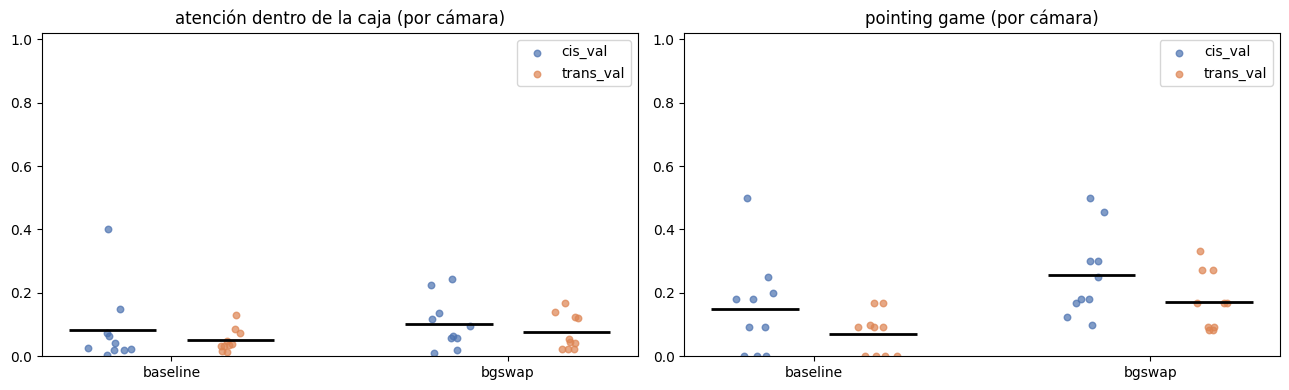

Lectura: si la atención dentro de la caja es baja y no mejora frente al área de la caja, el modelo apoya su decisión en el contexto. Si cae en trans_val respecto a cis_val, el foco se dispersa en fondos nuevos.


In [ ]:
N_PER_CAM = 12                 # imágenes con animal por cámara
MIN_AREA, MAX_AREA = 0.001, 0.5

def cam_study(arm, n_per_cam=N_PER_CAM):
    gc = GradCAMYolo(U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt')
    rows = []
    for s in ['cis_val', 'trans_val']:
        S = sample_with_animals(s, n_per_cam)
        for r in tqdm(S.itertuples(), total=len(S), desc=f'Grad-CAM {arm}/{s}'):
            im = Image.open(U.LOCAL / 'images' / s / r.file).convert('RGB')
            bx = read_boxes(s, r.file)
            cam, sc, c = gc(im)
            m = cam_metrics(cam, bx)
            if m and MIN_AREA <= m['area'] <= MAX_AREA:
                rows.append(dict(arm=arm, split=s, location=str(r.location), file=r.file, score=sc, **m))
    gc.close()
    return pd.DataFrame(rows)

CAMDF = pd.concat([cam_study(a) for a in arms_done], ignore_index=True)
CAMDF.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_gradcam_por_imagen.csv', index=False)
PCc = CAMDF.groupby(['arm', 'split', 'location']).agg(exceso=('exceso', 'mean'), energy_in=('energy_in', 'mean'), area=('area', 'mean'),
                                                      ratio=('ratio', 'median'), hit=('hit', 'mean'), n=('file', 'size')).reset_index()
rows = []
for arm in arms_done:
    a_, b_ = (PCc[(PCc.arm == arm) & (PCc.split == s)] for s in ['cis_val', 'trans_val'])
    for met, label in [('energy_in', 'atención dentro de la caja'), ('exceso', 'exceso de atención (dentro − área)'),
                       ('hit', 'pointing game'), ('ratio', 'razón atención/área (mediana)')]:
        lo, hi = boot_gap(a_[met], b_[met])
        rows.append(dict(brazo=arm, metrica=label, cis=a_[met].mean(), trans=b_[met].mean(), dif_cis_menos_trans=a_[met].mean() - b_[met].mean(),
                         IC95_inf=lo, IC95_sup=hi, n_cams_cis=len(a_), n_cams_trans=len(b_)))
CAMSTAT = pd.DataFrame(rows)
print('GRAD-CAM: ¿se concentra la atención en el animal? (media por cámara; n real = nº de cámaras)')
print(CAMSTAT.round(3).to_string(index=False))
CAMSTAT.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_gradcam_resumen.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4)); jr = np.random.default_rng(2)
for a_, met, tt in zip(ax, ['energy_in', 'hit'], ['atención dentro de la caja', 'pointing game']):
    for i, arm in enumerate(arms_done):
        for k, (s, col) in enumerate([('cis_val', '#4C72B0'), ('trans_val', '#DD8452')]):
            v = PCc[(PCc.arm == arm) & (PCc.split == s)][met].values; xx = i + (k - .5) * .35
            a_.scatter(xx + jr.normal(0, .03, len(v)), v, s=22, alpha=.7, color=col, label=s if i == 0 else None)
            a_.hlines(v.mean(), xx - .13, xx + .13, color='k', lw=2)
    a_.set_xticks(range(len(arms_done))); a_.set_xticklabels(arms_done); a_.set_ylim(0, 1.02); a_.set_title(tt + ' (por cámara)'); a_.legend()
plt.tight_layout(); plt.show()
print('Lectura: si la atención dentro de la caja es baja y no mejora frente al área de la caja, el modelo apoya su decisión en el contexto. '
      'Si cae en trans_val respecto a cis_val, el foco se dispersa en fondos nuevos.')

## 6.3 Entregable 3 · Pruebas contrafactuales (causales) sobre el fondo

Grad-CAM *sugiere* dónde mira el modelo; estas dos pruebas *intervienen* sobre la imagen:

**A. Quitar el animal.** Se borra cada animal con *inpainting* (`cv2.inpaint`). Se parte solo de imágenes donde el modelo detectaba correctamente al animal. Una detección que **sigue apareciendo sin animal** (*detección fantasma*) solo puede deberse al contexto/fondo. Referencia: la tasa de falsas alarmas del modelo sobre imágenes realmente vacías (sección 4).

**B. Cambiar el fondo manteniendo el animal.** El mismo recorte del animal (mismo tamaño relativo y posición) se pega sobre tres fondos vacíos: de **su propia cámara**, de **otra cámara de entrenamiento** y de **una cámara nueva**. Solo cambia el fondo. Si el *recall* es mayor sobre fondos de cámaras vistas que sobre fondos nuevos —incluso cuando el animal viene de una cámara nueva—, el modelo usa la familiaridad del fondo.

> Precaución sobre `bgswap`: fue entrenado con pegados rectangulares de este mismo tipo, así que la prueba B está contaminada a su favor; interpretarla con cuidado.

In [ ]:
def predict_pil(model, ims, conf=0.05, bs=32):
    out = []
    for i in range(0, len(ims), bs):
        arr = [np.asarray(im)[..., ::-1].copy() for im in ims[i:i + bs]]       # Ultralytics espera BGR en arrays
        out += model.predict(arr, conf=conf, iou=0.6, imgsz=U.IMGSZ, verbose=False)
    return out

def det_has(res, classes, thr, box=None, iou_min=0.5):
    """¿Hay alguna detección de una clase de `classes` con conf >= thr (y IoU >= iou_min con `box`, si se da)?"""
    b = res.boxes
    if b is None or len(b) == 0:
        return False
    cls, cf, xy = b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxyn.cpu().numpy()
    for k in range(len(cls)):
        if cls[k] in classes and cf[k] >= thr and (box is None or iou(xy[k].tolist(), list(box)) >= iou_min):
            return True
    return False

def remove_animals(im, boxes, pad=0.05):
    arr = np.asarray(im); H, W = arr.shape[:2]
    mask = np.zeros((H, W), np.uint8)
    for x1, y1, x2, y2, _ in boxes:
        bw, bh = x2 - x1, y2 - y1
        mask[max(0, int((y1 - pad * bh) * H)):min(H, int(math.ceil((y2 + pad * bh) * H))),
             max(0, int((x1 - pad * bw) * W)):min(W, int(math.ceil((x2 + pad * bw) * W)))] = 255
    return Image.fromarray(cv2.inpaint(arr, mask, 5, cv2.INPAINT_TELEA))

def paste_animal(src, box, bg):
    """Pega el recorte del animal de `src` sobre `bg` conservando tamaño relativo y posición. Devuelve (imagen, caja normalizada)."""
    Ws, Hs = src.size; Wb, Hb = bg.size
    x1, y1, x2, y2 = box
    bx1, by1, bx2, by2 = x1 * Ws, y1 * Hs, x2 * Ws, y2 * Hs
    mx, my = (bx2 - bx1) * .10, (by2 - by1) * .10
    c = (int(max(0, bx1 - mx)), int(max(0, by1 - my)), int(min(Ws, bx2 + mx)), int(min(Hs, by2 + my)))
    crop = src.crop(c); k = Wb / Ws
    nw, nh = max(8, int(crop.width * k)), max(8, int(crop.height * k))
    if nw >= Wb or nh >= Hb:
        return None
    crop = crop.resize((nw, nh), Image.BILINEAR)
    ix1, iy1, ix2, iy2 = (bx1 - c[0]) * k, (by1 - c[1]) * k, (bx2 - c[0]) * k, (by2 - c[1]) * k
    px = int(np.clip((x1 + x2) / 2 * Wb - (ix1 + ix2) / 2, 0, Wb - nw)); py = int(np.clip((y1 + y2) / 2 * Hb - (iy1 + iy2) / 2, 0, Hb - nh))
    lum_bg = np.asarray(bg.crop((px, py, px + nw, py + nh)).convert('L'), dtype=float).mean() + 1e-6
    lum_cr = np.asarray(crop.convert('L'), dtype=float).mean() + 1e-6
    crop = ImageEnhance.Brightness(crop).enhance(float(np.clip(lum_bg / lum_cr, 0.7, 1.3)))
    f_ = max(2, int(0.05 * min(nw, nh)))
    mask = Image.new('L', (nw, nh), 0); ImageDraw.Draw(mask).rectangle([f_, f_, nw - f_, nh - f_], fill=255)
    out = bg.copy(); out.paste(crop, (px, py), mask.filter(ImageFilter.GaussianBlur(f_ / 2 + 1)))
    return out, ((px + ix1) / Wb, (py + iy1) / Hb, (px + ix2) / Wb, (py + iy2) / Hb)

DETECCIONES FANTASMA tras borrar el animal (fracción de imágenes que conservan una detección de la misma especie)
   brazo  fantasma_cis  fantasma_trans   dif  IC95_inf  IC95_sup  falsa_alarma_vacias_cis  falsa_alarma_vacias_trans  n_imgs  n_cams_cis  n_cams_trans
baseline         0.253           0.146 0.107    -0.108     0.283                    0.136                      0.246     205          10            10
  bgswap         0.152           0.137 0.016    -0.184     0.190                    0.172                      0.301     204          10            10

Lectura: fantasma ≫ falsa alarma en vacías → el modelo se apoya en el contexto (o el inpainting deja restos del animal). fantasma_cis > fantasma_trans → el contexto de las cámaras VISTAS "sostiene" la detección: memorización de fondo.


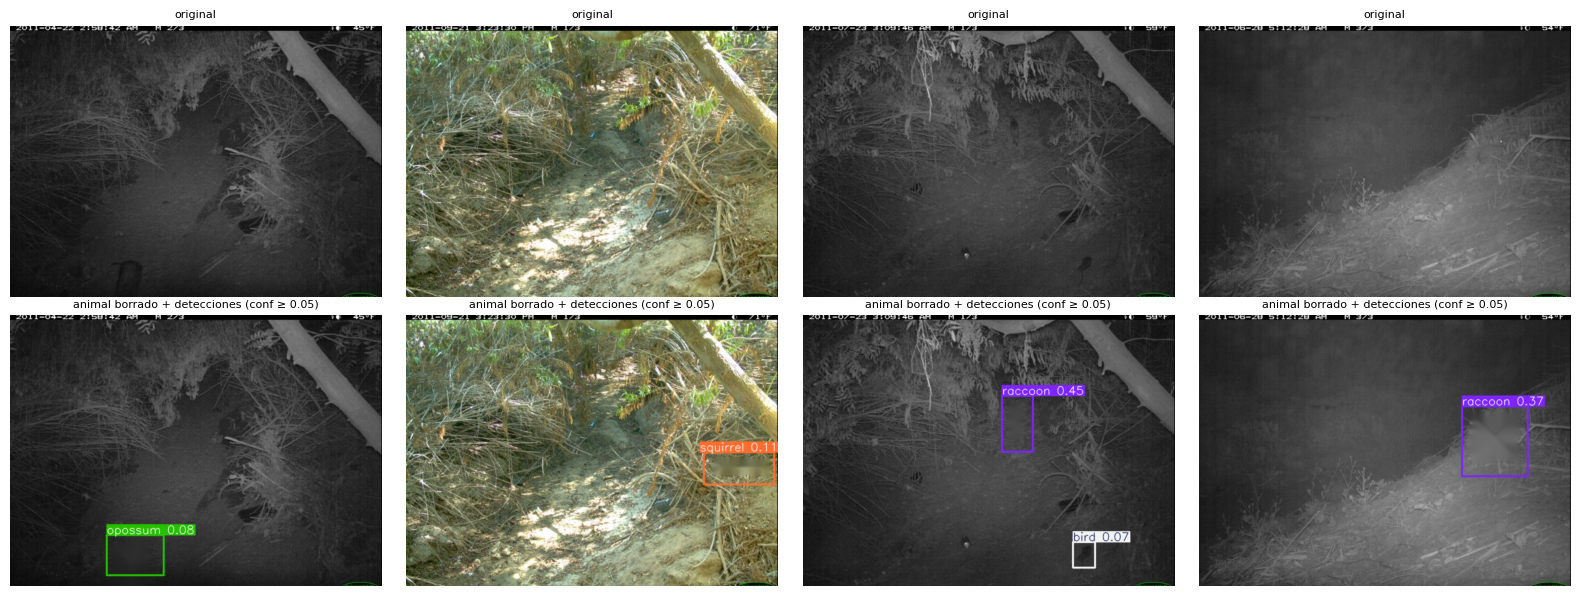

In [ ]:
# ---------- 6.3.A  Quitar el animal ----------
N_GHOST_PER_CAM = 12
rows = []
for arm in arms_done:
    model = YOLO(str(U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt'))
    for s in ['cis_val', 'trans_val']:
        S = sample_with_animals(s, N_GHOST_PER_CAM, seed=5)
        ims = [Image.open(U.LOCAL / 'images' / s / f).convert('RGB') for f in S.file]
        bxs = [read_boxes(s, f) for f in S.file]
        cls_sets = [{b[4] for b in bx} for bx in bxs]
        r0 = predict_pil(model, ims)
        ok = [det_has(r, cs, THR) for r, cs in zip(r0, cls_sets)]                 # detectado correctamente en la original
        idx = [i for i, o in enumerate(ok) if o]
        r1 = predict_pil(model, [remove_animals(ims[i], bxs[i]) for i in idx])
        ghost = {i: det_has(r, cls_sets[i], THR) for i, r in zip(idx, r1)}
        for i in idx:
            rows.append(dict(arm=arm, split=s, location=str(S.iloc[i]['location']), fantasma=float(ghost[i])))
GH = pd.DataFrame(rows)
GHc = GH.groupby(['arm', 'split', 'location']).fantasma.mean().reset_index()
out = []
for arm in arms_done:
    a_, b_ = (GHc[(GHc.arm == arm) & (GHc.split == s)].fantasma for s in ['cis_val', 'trans_val'])
    lo, hi = boot_gap(a_, b_)
    out.append(dict(brazo=arm, fantasma_cis=a_.mean(), fantasma_trans=b_.mean(), dif=a_.mean() - b_.mean(), IC95_inf=lo, IC95_sup=hi,
                    falsa_alarma_vacias_cis=R[(R.brazo == arm) & (R.split == 'cis_val')].falsas_alarmas_vacias.iloc[0],
                    falsa_alarma_vacias_trans=R[(R.brazo == arm) & (R.split == 'trans_val')].falsas_alarmas_vacias.iloc[0],
                    n_imgs=int(len(GH[GH.arm == arm])), n_cams_cis=len(a_), n_cams_trans=len(b_)))
GHOST = pd.DataFrame(out)
print('DETECCIONES FANTASMA tras borrar el animal (fracción de imágenes que conservan una detección de la misma especie)')
print(GHOST.round(3).to_string(index=False))
GHOST.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_fantasmas.csv', index=False)
print('\nLectura: fantasma ≫ falsa alarma en vacías → el modelo se apoya en el contexto (o el inpainting deja restos del animal). '
      'fantasma_cis > fantasma_trans → el contexto de las cámaras VISTAS "sostiene" la detección: memorización de fondo.')

# ejemplo visual
_m = YOLO(str(U.DRIVE_DIR / 'runs' / BASELINE_RUN / 'weights' / 'best.pt'))
_S = sample_with_animals('cis_val', 3, seed=11).head(4)
_ims = [Image.open(U.LOCAL / 'images' / 'cis_val' / f).convert('RGB') for f in _S.file]
_rm = [remove_animals(im, read_boxes('cis_val', f)) for im, f in zip(_ims, _S.file)]
_r = predict_pil(_m, _rm)
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for k in range(len(_ims)):
    axs[0, k].imshow(_ims[k]); axs[0, k].axis('off'); axs[0, k].set_title('original', fontsize=8)
    axs[1, k].imshow(_r[k].plot()[..., ::-1]); axs[1, k].axis('off'); axs[1, k].set_title('animal borrado + detecciones (conf ≥ 0.05)', fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# ---------- 6.3.B  Cambiar el fondo conservando el animal ----------
N_SWAP_PER_CAM = 10
rs = random.Random(7)
def one_box_sources(split, n_per_cam):
    Ms = meta[(meta.split == split) & (meta.n_boxes == 1)]
    keep = []
    for _, g in Ms.groupby('location'):
        for r in g.sample(frac=1, random_state=7).itertuples():
            x1, y1, x2, y2, c = read_boxes(split, r.file)[0]
            Wi, Hi = Image.open(U.LOCAL / 'images' / split / r.file).size
            if (x2 - x1) * Wi >= 24 and (y2 - y1) * Hi >= 24 and (x2 - x1) * (y2 - y1) <= 0.4:
                keep.append(r)
            if sum(1 for k in keep if k.location == r.location) >= n_per_cam:
                break
    return keep

empt = {s: meta[(meta.split == s) & (meta.n_boxes == 0)] for s in ['cis_val', 'trans_val']}
def pick_bg(kind, split, loc):
    if kind == 'propia':
        pool = empt[split][empt[split].location == loc]
    elif kind == 'otra_vista':
        pool = empt['cis_val'][empt['cis_val'].location != loc]
    else:
        pool = empt['trans_val'][empt['trans_val'].location != loc]
    if len(pool) == 0:
        return None
    r = pool.iloc[rs.randrange(len(pool))]
    s = 'cis_val' if kind == 'otra_vista' else ('trans_val' if kind == 'otra_nueva' else split)
    return Image.open(U.LOCAL / 'images' / s / r.file).convert('RGB')

KINDS = ['propia', 'otra_vista', 'otra_nueva']
cases = []
for s in ['cis_val', 'trans_val']:
    for r in one_box_sources(s, N_SWAP_PER_CAM):
        src = Image.open(U.LOCAL / 'images' / s / r.file).convert('RGB')
        x1, y1, x2, y2, c = read_boxes(s, r.file)[0]
        for kind in KINDS:
            bg = pick_bg(kind, s, r.location)
            if bg is None:
                continue
            p = paste_animal(src, (x1, y1, x2, y2), bg)
            if p:
                cases.append(dict(split_origen=s, location=str(r.location), fondo=kind, cls=c, img=p[0], box=p[1]))
print(f'{len(cases)} imágenes compuestas')

rows = []
for arm in arms_done:
    model = YOLO(str(U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt'))
    rr = predict_pil(model, [c['img'] for c in cases])
    for c, r in zip(cases, rr):
        rows.append(dict(arm=arm, split_origen=c['split_origen'], location=c['location'], fondo=c['fondo'],
                         acierto=float(det_has(r, {c['cls']}, THR, box=c['box']))))
SW = pd.DataFrame(rows)
SWc = SW.groupby(['arm', 'split_origen', 'fondo', 'location']).acierto.mean().reset_index()
tabsw = SWc.groupby(['arm', 'split_origen', 'fondo']).acierto.mean().unstack('fondo')[KINDS]
tabsw['ventaja_fondo_visto'] = tabsw['otra_vista'] - tabsw['otra_nueva']
print('RECALL (detección correcta, conf ≥ THR e IoU ≥ 0.5) del MISMO animal según el fondo sobre el que se pega')
print(tabsw.round(3).to_string())
out = []
for arm in arms_done:
    for s in ['cis_val', 'trans_val']:
        a_ = SWc[(SWc.arm == arm) & (SWc.split_origen == s) & (SWc.fondo == 'otra_vista')].set_index('location').acierto
        b_ = SWc[(SWc.arm == arm) & (SWc.split_origen == s) & (SWc.fondo == 'otra_nueva')].set_index('location').acierto
        d = (a_ - b_).dropna().values
        lo, hi = (np.nan, np.nan) if len(d) < 2 else np.percentile([np.random.default_rng(i).choice(d, len(d)).mean() for i in range(3000)], [2.5, 97.5])
        out.append(dict(brazo=arm, animal_de=s, ventaja_fondo_visto=d.mean() if len(d) else np.nan, IC95_inf=lo, IC95_sup=hi, n_cams=len(d)))
SWSTAT = pd.DataFrame(out)
print('\nVentaja de un fondo de cámara VISTA sobre uno NUEVO (bootstrap sobre cámaras de origen del animal):')
print(SWSTAT.round(3).to_string(index=False))
SWSTAT.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_intercambio_fondo.csv', index=False)
print('\nLectura: ventaja > 0 con IC que excluye 0 = el modelo detecta mejor el mismo animal cuando el fondo le resulta conocido '
      '(aunque el animal provenga de una cámara nueva) → usa el fondo como pista. Comparar `propia` vs `otra_*` controla el artefacto del pegado.')

597 imágenes compuestas
RECALL (detección correcta, conf ≥ THR e IoU ≥ 0.5) del MISMO animal según el fondo sobre el que se pega
fondo                  propia  otra_vista  otra_nueva  ventaja_fondo_visto
arm      split_origen                                                     
baseline cis_val         0.80       0.667       0.739               -0.072
         trans_val       0.66       0.580       0.590               -0.010
bgswap   cis_val         0.92       0.890       0.900               -0.010
         trans_val       0.79       0.830       0.790                0.040

Ventaja de un fondo de cámara VISTA sobre uno NUEVO (bootstrap sobre cámaras de origen del animal):
   brazo animal_de  ventaja_fondo_visto  IC95_inf  IC95_sup  n_cams
baseline   cis_val               -0.072    -0.134     -0.01      10
baseline trans_val               -0.010    -0.100      0.08      10
  bgswap   cis_val               -0.010    -0.040      0.02      10
  bgswap trans_val                0.040    -0.00

## 6.4 Entregable 3 · Síntesis de la evidencia

In [ ]:
ev = []
for arm in arms_done:
    g = lambda met, s: CAMSTAT[(CAMSTAT.brazo == arm) & (CAMSTAT.metrica == met)][s].iloc[0]
    gp = lambda met: GAP[(GAP.brazo == arm) & (GAP.metrica == met)]
    ev.append(dict(
        brazo=arm,
        brecha_mAP50=gp('mAP50').brecha.iloc[0], IC_mAP50=f"[{gp('mAP50').IC95_inf.iloc[0]:+.2f}, {gp('mAP50').IC95_sup.iloc[0]:+.2f}]",
        brecha_mAP50_95=gp('mAP50_95').brecha.iloc[0],
        CAM_en_caja_cis=g('atención dentro de la caja', 'cis'), CAM_en_caja_trans=g('atención dentro de la caja', 'trans'),
        pointing_cis=g('pointing game', 'cis'), pointing_trans=g('pointing game', 'trans'),
        fantasma_cis=GHOST[GHOST.brazo == arm].fantasma_cis.iloc[0], fantasma_trans=GHOST[GHOST.brazo == arm].fantasma_trans.iloc[0],
        ventaja_fondo_visto_animal_nuevo=SWSTAT[(SWSTAT.brazo == arm) & (SWSTAT.animal_de == 'trans_val')].ventaja_fondo_visto.iloc[0]))
EVID = pd.DataFrame(ev)
print('SÍNTESIS: brecha de rendimiento + evidencia de dependencia del fondo')
print(EVID.round(3).T.to_string(header=False) if len(EVID) == 1 else EVID.round(3).to_string(index=False))
EVID.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable3_sintesis.csv', index=False)

print("""
CÓMO LEERLO
• brecha_mAP* > 0 con IC95% que excluye 0  → el modelo rinde peor en cámaras nuevas.
• CAM_en_caja bajo (cercano al área de la caja) o que cae de cis a trans → la atención no se concentra en el animal.
• fantasma_cis alto (y > fantasma_trans) → detecciones que persisten sin animal: el contexto de cámaras vistas sostiene la decisión.
• ventaja_fondo_visto > 0 → el mismo animal se detecta mejor sobre fondos de cámaras vistas: familiaridad del fondo.
• Si un brazo (strong_aug / bgswap) reduce la brecha Y mejora estos indicadores, hay evidencia indirecta de que la dependencia del fondo
  era parte de la causa. Si la brecha baja pero estos indicadores no cambian, la mejora viene de otra vía.
Limitaciones: una semilla, ~10 cámaras nuevas, Grad-CAM de baja resolución, inpainting/pegado rectangular imperfectos.""")

SÍNTESIS: brecha de rendimiento + evidencia de dependencia del fondo
   brazo  brecha_mAP50       IC_mAP50  brecha_mAP50_95  CAM_en_caja_cis  CAM_en_caja_trans  pointing_cis  pointing_trans  fantasma_cis  fantasma_trans  ventaja_fondo_visto_animal_nuevo
baseline         0.296 [+0.19, +0.39]            0.216            0.082              0.051         0.150           0.071         0.253           0.146                             -0.01
  bgswap         0.272 [+0.18, +0.36]            0.191            0.103              0.076         0.256           0.173         0.152           0.137                              0.04

CÓMO LEERLO
• brecha_mAP* > 0 con IC95% que excluye 0  → el modelo rinde peor en cámaras nuevas.
• CAM_en_caja bajo (cercano al área de la caja) o que cae de cis a trans → la atención no se concentra en el animal.
• fantasma_cis alto (y > fantasma_trans) → detecciones que persisten sin animal: el contexto de cámaras vistas sostiene la decisión.
• ventaja_fondo_visto > 0 → 

## 6.5 Entregable 4 · Robustez ante oclusión y tamaño del objeto (conjunto de prueba)

**Conjunto:** `trans_val` (cámaras nuevas), con las detecciones ya guardadas de cada brazo (`preds_all`, `conf ≥ 0.05`) y las cajas reales.

**Tamaño relativo** = área de la caja / área de la imagen: *pequeño* (< 1 %), *mediano* (1–10 %), *grande* (> 10 %).

**Oclusión.** CCT-20 **no trae etiquetas de oclusión**, así que se *estima* con un proxy geométrico calculado desde las cajas reales:
- *truncamiento por el borde*: nº de lados de la caja pegados al borde de la imagen (animal cortado por el encuadre);
- *solapamiento*: fracción de la caja cubierta por otra caja de animal.

| Nivel | Regla |
|---|---|
| **bajo** | no toca el borde y solapamiento < 10 % |
| **medio** | toca 1 borde, o solapamiento 10–30 % |
| **alto** | toca ≥ 2 bordes (esquina), o solapamiento ≥ 30 % |

> El proxy **no captura oclusión por vegetación u objetos del primer plano**, que es la más común en cámaras trampa. Por eso se complementa con un experimento **controlado** (sección 6.5.C): se ocluye artificialmente 25 / 50 / 75 % de la caja del animal con un parche de textura del propio fondo y se mide cuánto cae la detección.

**Métricas por grupo:** *recall@THR* (fracción de animales detectados con la especie correcta, IoU ≥ 0.5 y confianza ≥ umbral operativo), *recall@0.05* (potencial máximo), IoU medio de los aciertos y **AP@0.5** macro (las instancias de otros grupos se ignoran, como en la evaluación por tamaño de COCO). **Caída = mejor grupo − peor grupo.** El IC 95 % de la caída de recall se obtiene por *bootstrap sobre cámaras*.

In [ ]:
ROB_SPLIT = 'trans_val'
SIZE_BINS = [0, 0.01, 0.10, 1.0001]
SIZE_LABELS = ['pequeño (<1%)', 'mediano (1–10%)', 'grande (>10%)']
OCC_LABELS = ['bajo', 'medio', 'alto']
EDGE_M, MIN_N_GROUP = 0.005, 30

def build_gt(split):
    rows = []
    Ms = meta[(meta.split == split) & (meta.n_boxes > 0)]
    for r in Ms.itertuples():
        bx = []
        for l in (U.LOCAL / 'labels' / split / (Path(r.file).stem + '.txt')).read_text().splitlines():
            if l.strip():
                c, xc, yc, w, h = l.split(); c = int(c); xc, yc, w, h = map(float, (xc, yc, w, h))
                bx.append((c, xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2))
        for i, (c, x1, y1, x2, y2) in enumerate(bx):
            a = (x2 - x1) * (y2 - y1); ioa = 0.
            for j, (_, a1, b1, a2, b2) in enumerate(bx):
                if j != i:
                    ioa = max(ioa, max(0, min(x2, a2) - max(x1, a1)) * max(0, min(y2, b2) - max(y1, b1)) / max(a, 1e-9))
            sides = int(x1 <= EDGE_M) + int(y1 <= EDGE_M) + int(x2 >= 1 - EDGE_M) + int(y2 >= 1 - EDGE_M)
            rows.append(dict(file=r.file, location=str(r.location), cls=U.CLASSES[c], x1=x1, y1=y1, x2=x2, y2=y2,
                             area=a, sides=sides, ioa=ioa, n_boxes_img=len(bx)))
    G = pd.DataFrame(rows)
    G['occ'] = np.where((G.sides >= 2) | (G.ioa >= .30), 'alto', np.where((G.sides == 1) | (G.ioa >= .10), 'medio', 'bajo'))
    G['tam'] = pd.cut(G['area'], bins=SIZE_BINS, labels=SIZE_LABELS).astype(str)
    return G

GT = build_gt(ROB_SPLIT)
print(f'{ROB_SPLIT}: {len(GT):,} animales en {GT.file.nunique():,} imágenes y {GT.location.nunique()} cámaras')
print('\nDistribución de grupos (instancias):')
dist = pd.concat([GT.tam.value_counts().reindex(SIZE_LABELS).rename('tamaño'),
                  GT.occ.value_counts().reindex(OCC_LABELS).rename('oclusión estimada')], axis=1)
print(dist.to_string())
print('\nCruce tamaño × oclusión (¿están confundidos? p. ej. los truncados suelen ser grandes):')
print(pd.crosstab(GT.tam, GT.occ).reindex(index=SIZE_LABELS, columns=OCC_LABELS).fillna(0).astype(int).to_string())
small_groups = [g for g in SIZE_LABELS if (GT.tam == g).sum() < MIN_N_GROUP] + [g for g in OCC_LABELS if (GT.occ == g).sum() < MIN_N_GROUP]
if small_groups:
    print(f'\nATENCIÓN: grupos con < {MIN_N_GROUP} instancias (resultados poco fiables):', small_groups)

trans_val: 9,356 animales en 9,014 imágenes y 10 cámaras

Distribución de grupos (instancias):
                 tamaño  oclusión estimada
pequeño (<1%)     983.0                NaN
mediano (1–10%)  7022.0                NaN
grande (>10%)    1351.0                NaN
bajo                NaN             6946.0
medio               NaN             1471.0
alto                NaN              939.0

Cruce tamaño × oclusión (¿están confundidos? p. ej. los truncados suelen ser grandes):
occ              bajo  medio  alto
tam                               
pequeño (<1%)     897     81     5
mediano (1–10%)  5882   1020   120
grande (>10%)     167    370   814


In [ ]:
def iou_vec(b, B):
    ix = np.clip(np.minimum(b[2], B[:, 2]) - np.maximum(b[0], B[:, 0]), 0, None)
    iy = np.clip(np.minimum(b[3], B[:, 3]) - np.maximum(b[1], B[:, 1]), 0, None)
    inter = ix * iy
    return inter / ((b[2] - b[0]) * (b[3] - b[1]) + (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1]) - inter + 1e-9)

def match_instances(G, P, thr):
    """Por cada animal real: mejor confianza de una predicción de su especie con IoU ≥ 0.5."""
    Pg = {f: (g['cls'].values, g['conf'].values, g[['x1', 'y1', 'x2', 'y2']].values) for f, g in P.groupby('file')}
    bc, bi = np.zeros(len(G)), np.zeros(len(G))
    for k, r in enumerate(G.itertuples()):
        pr = Pg.get(r.file)
        if pr is None:
            continue
        cls, cf, B = pr; m = cls == r.cls
        if not m.any():
            continue
        ious = iou_vec(np.array([r.x1, r.y1, r.x2, r.y2]), B[m]); ok = ious >= .5
        if ok.any():
            bc[k] = cf[m][ok].max(); bi[k] = ious[ok][cf[m][ok].argmax()]
    out = G.copy(); out['conf_match'], out['iou_match'] = bc, bi
    out['det'], out['det_any'] = bc >= THR, bc > 0
    return out

def greedy_match_preds(G, P):
    """Empareja uno a uno (por confianza descendente) cada predicción con un animal real de su especie, IoU ≥ 0.5."""
    P = P.sort_values('conf', ascending=False).reset_index(drop=True)
    gt_by = {k: (g.index.values, g[['x1', 'y1', 'x2', 'y2']].values) for k, g in G.groupby(['file', 'cls'])}
    used, gi = np.zeros(len(G), bool), np.full(len(P), -1)
    for k, (f, c, b) in enumerate(zip(P.file.values, P.cls.values, P[['x1', 'y1', 'x2', 'y2']].values)):
        e = gt_by.get((f, c))
        if e is None:
            continue
        idx, B = e; ious = iou_vec(b, B); ious[used[idx]] = -1
        j = int(ious.argmax())
        if ious[j] >= .5:
            gi[k] = idx[j]; used[idx[j]] = True
    P['gt_idx'] = gi; P['area_pred'] = (P.x2 - P.x1) * (P.y2 - P.y1)
    return P

def ap50_group(G, Pm, in_group, pred_keep=None, min_gt=5):
    """AP@0.5 macro sobre especies. Predicciones emparejadas con animales de OTRO grupo se ignoran;
    las no emparejadas son falsos positivos (salvo que `pred_keep` las excluya, como en COCO por tamaño)."""
    aps = []
    for c, gc in G.groupby('cls'):
        if int(in_group[gc.index].sum()) < min_gt:
            continue
        npos = int(in_group[gc.index].sum())
        pc = Pm[Pm.cls == c]; gi = pc['gt_idx'].values; matched = gi >= 0
        g_in = np.zeros(len(pc), bool); g_in[matched] = in_group[gi[matched]]
        ign = matched & ~g_in
        if pred_keep is not None:
            ign |= (~matched) & ~pred_keep(pc)
        tp = (matched & g_in)[~ign]; fp = (~matched)[~ign]
        if len(tp) == 0:
            aps.append(0.); continue
        ctp, cfp = np.cumsum(tp), np.cumsum(fp)
        rec_, pre_ = ctp / npos, ctp / np.maximum(ctp + cfp, 1)
        mrec, mpre = np.concatenate([[0], rec_, [1]]), np.concatenate([[1], pre_, [0]])
        mpre = np.maximum.accumulate(mpre[::-1])[::-1]
        xs = np.linspace(0, 1, 101)
        aps.append(float(mpre[np.searchsorted(mrec, xs, side='left')].mean()))
    return (float(np.mean(aps)) if aps else np.nan), len(aps)

def group_table(arm):
    P = preds_all[(arm, ROB_SPLIT)]
    Gm = match_instances(GT, P, THR); Pm = greedy_match_preds(GT, P)
    rows = []
    for factor, col, labels in [('tamaño', 'tam', SIZE_LABELS), ('oclusión estimada', 'occ', OCC_LABELS)]:
        for gi_, g in enumerate(labels):
            inn = (Gm[col] == g).values
            keep = None
            if factor == 'tamaño':
                lo, hi = SIZE_BINS[gi_], SIZE_BINS[gi_ + 1]
                keep = lambda pc, lo=lo, hi=hi: ((pc['area_pred'] >= lo) & (pc['area_pred'] < hi)).values
            ap, ncl = ap50_group(GT, Pm, inn, keep); sub = Gm[inn]
            rows.append(dict(brazo=arm, factor=factor, grupo=g, n_inst=int(inn.sum()), n_cams=sub.location.nunique(),
                             recall_THR=sub.det.mean() if len(sub) else np.nan, recall_005=sub.det_any.mean() if len(sub) else np.nan,
                             IoU_medio=sub.loc[sub.det_any, 'iou_match'].mean() if sub.det_any.any() else np.nan,
                             AP50=ap, n_especies_AP=ncl))
    return pd.DataFrame(rows), Gm

def boot_drop(Gm, col, g_hi, g_lo, n=3000, seed=0):
    """IC95% de recall(g_hi) − recall(g_lo) remuestreando cámaras (la unidad de generalización)."""
    a = Gm[Gm[col] == g_hi].groupby('location').det.agg(['sum', 'count'])
    b = Gm[Gm[col] == g_lo].groupby('location').det.agg(['sum', 'count'])
    cams = sorted(Gm.location.unique()); r = np.random.default_rng(seed); ds = []
    for _ in range(n):
        pick = r.choice(cams, len(cams)); ta, tb = a.reindex(pick).fillna(0), b.reindex(pick).fillna(0)
        if ta['count'].sum() > 0 and tb['count'].sum() > 0:
            ds.append(ta['sum'].sum() / ta['count'].sum() - tb['sum'].sum() / tb['count'].sum())
    return tuple(np.percentile(ds, [2.5, 97.5])) if ds else (np.nan, np.nan)

ROB, GM = [], {}
for arm in arms_done:
    t_, GM[arm] = group_table(arm); ROB.append(t_)
ROB = pd.concat(ROB, ignore_index=True)
print(f'DESEMPEÑO POR GRUPO en {ROB_SPLIT} (recall@THR con THR={THR})')
print(ROB.round(3).to_string(index=False))
ROB.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable4_desempeno_por_grupo.csv', index=False)

rows = []
for arm in arms_done:
    g = ROB[ROB.brazo == arm].set_index('grupo')
    for factor, col, hi, lo in [('tamaño: grande − pequeño', 'tam', SIZE_LABELS[2], SIZE_LABELS[0]),
                                ('tamaño: mediano − pequeño', 'tam', SIZE_LABELS[1], SIZE_LABELS[0]),
                                ('oclusión: bajo − alto', 'occ', 'bajo', 'alto'),
                                ('oclusión: bajo − medio', 'occ', 'bajo', 'medio')]:
        lo_ci, hi_ci = boot_drop(GM[arm], col, hi, lo)
        d_rec = g.loc[hi, 'recall_THR'] - g.loc[lo, 'recall_THR']
        rows.append(dict(brazo=arm, comparacion=factor, caida_recall=d_rec, IC95_inf=lo_ci, IC95_sup=hi_ci,
                         caida_relativa_pct=100 * d_rec / g.loc[hi, 'recall_THR'] if g.loc[hi, 'recall_THR'] else np.nan,
                         caida_AP50=g.loc[hi, 'AP50'] - g.loc[lo, 'AP50'], n_hi=int(g.loc[hi, 'n_inst']), n_lo=int(g.loc[lo, 'n_inst'])))
ROBDROP = pd.DataFrame(rows)
print('\nCAÍDA DE DESEMPEÑO ENTRE GRUPOS (mejor − peor; IC95% bootstrap sobre cámaras para el recall)')
print(ROBDROP.round(3).to_string(index=False))
ROBDROP.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable4_caida_entre_grupos.csv', index=False)
print('\nUn IC que excluye 0 indica una caída sistemática; con grupos pequeños el IC será ancho. '
      'AP50 usa predicciones con conf ≥ 0.05, por lo que es algo menor que el mAP oficial pero comparable entre grupos.')

DESEMPEÑO POR GRUPO en trans_val (recall@THR con THR=0.2)
   brazo            factor           grupo  n_inst  n_cams  recall_THR  recall_005  IoU_medio  AP50  n_especies_AP
baseline            tamaño   pequeño (<1%)     983      10       0.462       0.504      0.770 0.368             11
baseline            tamaño mediano (1–10%)    7022      10       0.782       0.808      0.819 0.567             11
baseline            tamaño   grande (>10%)    1351      10       0.614       0.625      0.962 0.346             10
baseline oclusión estimada            bajo    6946      10       0.777       0.803      0.814 0.483             12
baseline oclusión estimada           medio    1471      10       0.483       0.520      0.838 0.242              9
baseline oclusión estimada            alto     939      10       0.711       0.721      0.979 0.190              8
  bgswap            tamaño   pequeño (<1%)     983      10       0.485       0.538      0.769 0.392             11
  bgswap            ta

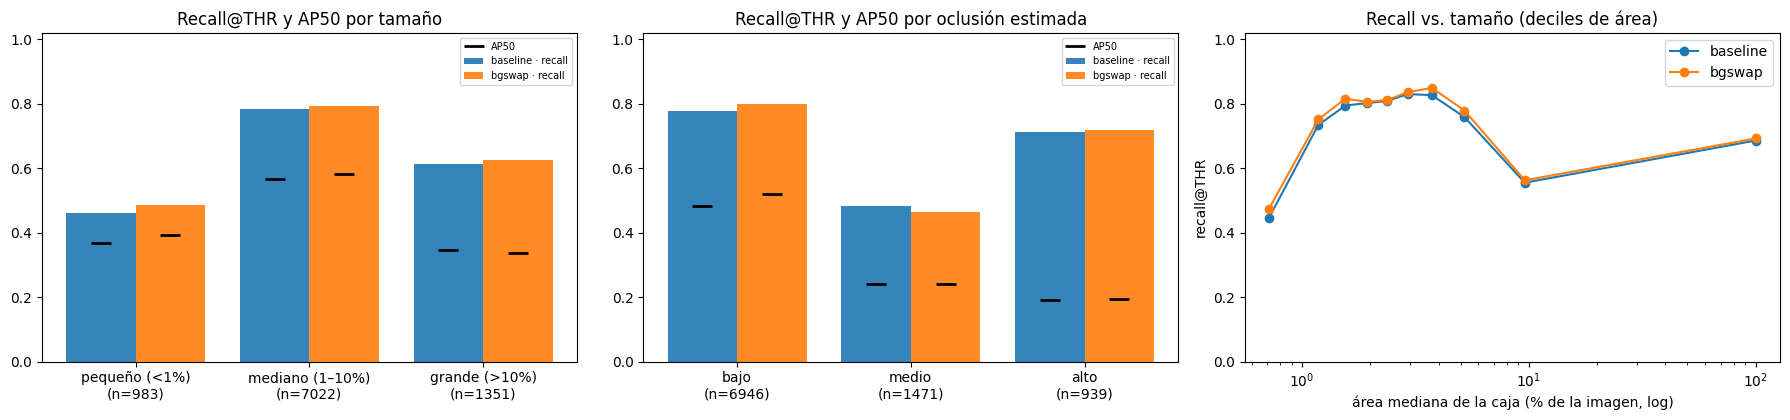

Recall@THR del baseline por tamaño × oclusión (celdas con n < 15 poco fiables)
occ               bajo  medio   alto
tam                                 
pequeño (<1%)    0.476  0.333    NaN
mediano (1–10%)  0.828  0.575  0.283
grande (>10%)    0.587  0.262  0.779

n por celda:
occ              bajo  medio  alto
tam                               
pequeño (<1%)     897     81     5
mediano (1–10%)  5882   1020   120
grande (>10%)     167    370   814


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3)); w = 0.8 / len(arms_done)
for a_, (factor, labels) in zip(ax[:2], [('tamaño', SIZE_LABELS), ('oclusión estimada', OCC_LABELS)]):
    for i, arm in enumerate(arms_done):
        d = ROB[(ROB.brazo == arm) & (ROB.factor == factor)].set_index('grupo').reindex(labels)
        a_.bar(np.arange(len(labels)) + i * w, d['recall_THR'], w, label=f'{arm} · recall', alpha=.9)
        a_.plot(np.arange(len(labels)) + i * w, d['AP50'], 'k_', ms=14, mew=2, label='AP50' if i == 0 else None)
    a_.set_xticks(np.arange(len(labels)) + w * (len(arms_done) - 1) / 2)
    a_.set_xticklabels([f'{l}\n(n={int((GT.tam if factor == "tamaño" else GT.occ).eq(l).sum())})' for l in labels])
    a_.set_ylim(0, 1.02); a_.set_title(f'Recall@THR y AP50 por {factor}'); a_.legend(fontsize=7)
# recall vs. tamaño continuo (deciles de área)
GT['dec'] = pd.qcut(GT['area'], 10, labels=False, duplicates='drop')
for arm in arms_done:
    Gm = GM[arm].assign(dec=GT['dec'].values)
    cur = Gm.groupby('dec').agg(area=('area', 'median'), rec=('det', 'mean'))
    ax[2].plot(cur['area'] * 100, cur['rec'], marker='o', label=arm)
ax[2].set_xscale('log'); ax[2].set_xlabel('área mediana de la caja (% de la imagen, log)'); ax[2].set_ylabel('recall@THR')
ax[2].set_title('Recall vs. tamaño (deciles de área)'); ax[2].set_ylim(0, 1.02); ax[2].legend()
plt.tight_layout(); plt.savefig(U.DRIVE_DIR / 'figs' / 'entregable4_tamano_oclusion.png', dpi=150); plt.show()

# Tamaño × oclusión (baseline): separa el efecto de ambos factores
Gb = GM[BASELINE_RUN]
ct_n = pd.crosstab(Gb.tam, Gb.occ).reindex(index=SIZE_LABELS, columns=OCC_LABELS).fillna(0).astype(int)
ct_r = Gb.pivot_table(index='tam', columns='occ', values='det', aggfunc='mean').reindex(index=SIZE_LABELS, columns=OCC_LABELS)
print('Recall@THR del baseline por tamaño × oclusión (celdas con n < 15 poco fiables)')
print(ct_r.where(ct_n >= 15).round(3).to_string()); print('\nn por celda:'); print(ct_n.to_string())

480 imágenes con oclusión artificial (120 animales × 4 niveles)
RECALL@THR (misma especie, IoU ≥ 0.5) según el % de la caja ocluido (media por cámara)
nivel     control (0%)  bajo (25%)  medio (50%)  alto (75%)
brazo                                                      
baseline         0.708       0.333        0.067         0.0
bgswap           0.717       0.367        0.075         0.0

CAÍDA respecto al control sin oclusión (IC95% bootstrap sobre cámaras):
   brazo    oclusion  caida_recall  IC95_inf  IC95_sup  caida_relativa_pct  n_cams
baseline  bajo (25%)         0.375     0.267     0.492              52.941      10
baseline medio (50%)         0.642     0.500     0.783              90.588      10
baseline  alto (75%)         0.708     0.558     0.842             100.000      10
  bgswap  bajo (25%)         0.350     0.267     0.442              48.837      10
  bgswap medio (50%)         0.642     0.525     0.767              89.535      10
  bgswap  alto (75%)         0.717    

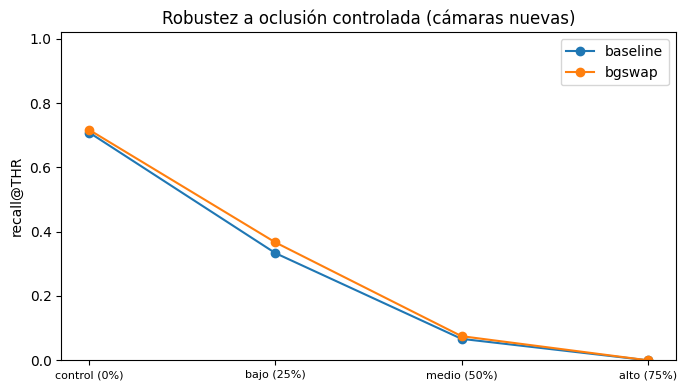

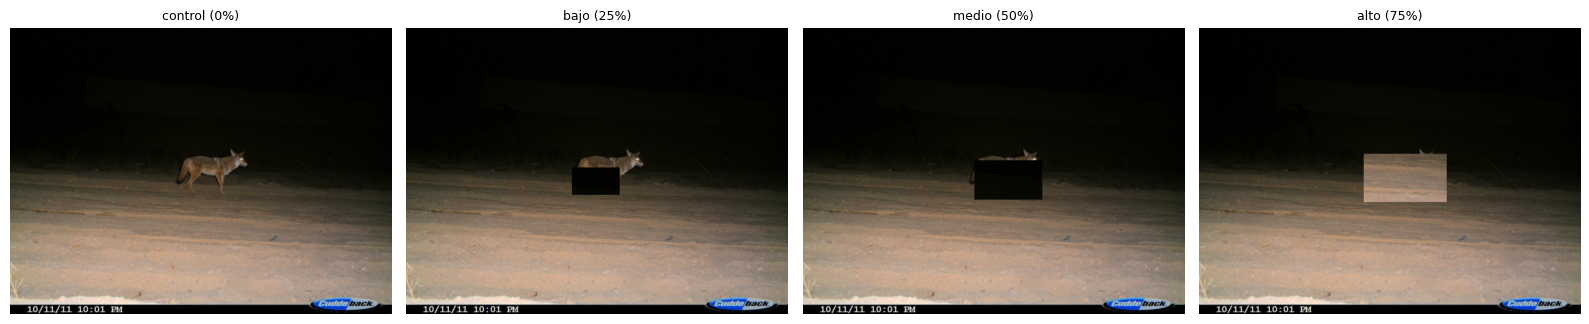

In [ ]:
# ---------- 6.5.C  Oclusión CONTROLADA: se tapa 25 / 50 / 75 % de la caja del animal ----------
import zlib
assert 'det_has' in globals() and 'predict_pil' in globals(), 'Ejecuta antes la celda de funciones auxiliares de la sección 6.3.'
N_OCC_PER_CAM = 12
OCC_LEVELS = [('control (0%)', 0.0), ('bajo (25%)', .25), ('medio (50%)', .50), ('alto (75%)', .75)]

def occlude_box(im, box, f, rnd):
    """Cubre una fracción f del área de la caja con un parche de textura tomado de otra zona de la misma imagen."""
    if f <= 0:
        return im
    W, H = im.size; x1, y1, x2, y2 = box[0] * W, box[1] * H, box[2] * W, box[3] * H
    k = math.sqrt(f); ow, oh = (x2 - x1) * k, (y2 - y1) * k
    ox, oy = rnd.uniform(x1, x2 - ow), rnd.uniform(y1, y2 - oh)
    patch = None
    for _ in range(30):
        sx, sy = rnd.uniform(0, max(0, W - ow)), rnd.uniform(0, max(0, H - oh))
        if sx + ow <= x1 or sx >= x2 or sy + oh <= y1 or sy >= y2:
            patch = im.crop((int(sx), int(sy), int(sx + ow), int(sy + oh))); break
    if patch is None:
        patch = Image.new('RGB', (max(1, int(ow)), max(1, int(oh))), (110, 110, 110))
    out = im.copy(); out.paste(patch.resize((max(1, int(ow)), max(1, int(oh)))), (int(ox), int(oy)))
    return out

One = GT[(GT.n_boxes_img == 1) & (GT.area >= 0.005) & (GT.area <= 0.6)]
cases = []
for loc, g in One.groupby('location'):
    for r in g.sample(min(len(g), N_OCC_PER_CAM), random_state=11).itertuples():
        im = Image.open(U.LOCAL / 'images' / ROB_SPLIT / r.file).convert('RGB')
        box = (r.x1, r.y1, r.x2, r.y2)
        for name, f in OCC_LEVELS:
            rnd = random.Random(zlib.crc32(r.file.encode()) + int(f * 100))
            cases.append(dict(nivel=name, location=str(loc), cid=U.CLASSES.index(r.cls), box=box, img=occlude_box(im, box, f, rnd)))
print(f'{len(cases)} imágenes con oclusión artificial ({len(cases) // len(OCC_LEVELS)} animales × {len(OCC_LEVELS)} niveles)')

rows = []
for arm in arms_done:
    model = YOLO(str(U.DRIVE_DIR / 'runs' / arm / 'weights' / 'best.pt'))
    for c, r in zip(cases, predict_pil(model, [c['img'] for c in cases])):
        rows.append(dict(brazo=arm, nivel=c['nivel'], location=c['location'], acierto=float(det_has(r, {c['cid']}, THR, box=c['box']))))
SO = pd.DataFrame(rows)
SOc = SO.groupby(['brazo', 'nivel', 'location']).acierto.mean().reset_index()
order = [n for n, _ in OCC_LEVELS]
tabo = SOc.groupby(['brazo', 'nivel']).acierto.mean().unstack('nivel')[order]
print('RECALL@THR (misma especie, IoU ≥ 0.5) según el % de la caja ocluido (media por cámara)')
print(tabo.round(3).to_string())
rows = []
for arm in arms_done:
    ctrl = SOc[(SOc.brazo == arm) & (SOc.nivel == order[0])].set_index('location').acierto
    for n in order[1:]:
        d = (ctrl - SOc[(SOc.brazo == arm) & (SOc.nivel == n)].set_index('location').acierto).dropna().values
        ci = np.percentile([np.random.default_rng(i).choice(d, len(d)).mean() for i in range(3000)], [2.5, 97.5]) if len(d) > 1 else (np.nan, np.nan)
        rows.append(dict(brazo=arm, oclusion=n, caida_recall=d.mean(), IC95_inf=ci[0], IC95_sup=ci[1],
                         caida_relativa_pct=100 * d.mean() / ctrl.mean() if ctrl.mean() else np.nan, n_cams=len(d)))
OCCDROP = pd.DataFrame(rows)
print('\nCAÍDA respecto al control sin oclusión (IC95% bootstrap sobre cámaras):')
print(OCCDROP.round(3).to_string(index=False))
OCCDROP.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable4_oclusion_controlada.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for arm in arms_done:
    ax.plot(range(len(order)), tabo.loc[arm, order].values, marker='o', label=arm)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=8); ax.set_ylim(0, 1.02)
ax.set_ylabel('recall@THR'); ax.set_title('Robustez a oclusión controlada (cámaras nuevas)'); ax.legend()
plt.tight_layout(); plt.savefig(U.DRIVE_DIR / 'figs' / 'entregable4_oclusion_controlada.png', dpi=150); plt.show()

# ejemplo visual
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4)); ex = [c for c in cases if c['location'] == cases[0]['location']][:4]
for a_, c in zip(axs, ex):
    a_.imshow(c['img']); a_.set_title(c['nivel'], fontsize=9); a_.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for arm in arms_done:
    d = ROBDROP[ROBDROP.brazo == arm].set_index('comparacion'); o = OCCDROP[OCCDROP.brazo == arm].set_index('oclusion')
    rows.append(dict(brazo=arm,
        caida_recall_tam_grande_vs_pequeño=d.loc['tamaño: grande − pequeño', 'caida_recall'],
        IC_tam=f"[{d.loc['tamaño: grande − pequeño', 'IC95_inf']:+.2f}, {d.loc['tamaño: grande − pequeño', 'IC95_sup']:+.2f}]",
        caida_AP50_tam=d.loc['tamaño: grande − pequeño', 'caida_AP50'],
        caida_recall_occ_natural_bajo_vs_alto=d.loc['oclusión: bajo − alto', 'caida_recall'],
        IC_occ_nat=f"[{d.loc['oclusión: bajo − alto', 'IC95_inf']:+.2f}, {d.loc['oclusión: bajo − alto', 'IC95_sup']:+.2f}]",
        caida_recall_occ_controlada_50=o.loc['medio (50%)', 'caida_recall'], caida_recall_occ_controlada_75=o.loc['alto (75%)', 'caida_recall']))
ROBSYN = pd.DataFrame(rows)
print('SÍNTESIS · ¿cuánto cae el desempeño con objetos pequeños y ocluidos?')
print(ROBSYN.round(3).T.to_string(header=False) if len(ROBSYN) == 1 else ROBSYN.round(3).to_string(index=False))
ROBSYN.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable4_sintesis.csv', index=False)
print("""
CÓMO LEERLO
• Caída por tamaño: diferencia de recall entre animales grandes y pequeños. Las cámaras trampa suelen mostrar la mayor pérdida en animales < 1 % de la imagen.
• Caída por oclusión natural: usa un proxy geométrico (borde/solapamiento); no ve vegetación. Está confundida con el tamaño (ver el cruce tamaño × oclusión).
• Caída por oclusión controlada: es causal (mismo animal, mismo fondo, solo cambia el % tapado) y es la cifra más defendible para hablar de robustez.
• Si un brazo (strong_aug / bgswap) reduce estas caídas, el aumento de datos mejora la robustez además de la brecha entre cámaras.
Limitaciones: parche de textura ≠ vegetación real; proxy de oclusión sin etiquetas humanas; grupos 'alto' pequeños; una semilla.""")

SÍNTESIS · ¿cuánto cae el desempeño con objetos pequeños y ocluidos?
   brazo  caida_recall_tam_grande_vs_pequeño         IC_tam  caida_AP50_tam  caida_recall_occ_natural_bajo_vs_alto     IC_occ_nat  caida_recall_occ_controlada_50  caida_recall_occ_controlada_75
baseline                               0.152 [-0.34, +0.50]          -0.022                                  0.066 [-0.16, +0.68]                           0.642                           0.708
  bgswap                               0.141 [-0.34, +0.48]          -0.056                                  0.078 [-0.14, +0.69]                           0.642                           0.717

CÓMO LEERLO
• Caída por tamaño: diferencia de recall entre animales grandes y pequeños. Las cámaras trampa suelen mostrar la mayor pérdida en animales < 1 % de la imagen.
• Caída por oclusión natural: usa un proxy geométrico (borde/solapamiento); no ve vegetación. Está confundida con el tamaño (ver el cruce tamaño × oclusión).
• Caída por oclusió

## 7. Interpretación (completar en el informe)
1. ¿Qué tan grande es la brecha cis−trans del baseline, en mAP50 y en F1 de imagen? ¿Es mayor en especies raras?
2. ¿Las falsas alarmas sobre vacías suben en cámaras nuevas? ¿Qué fondos las provocan (ver notebook 02, sección 7)?
3. ¿El intercambio de fondo + aumento fuerte reduce la brecha? ¿A costa de qué (mAP en cis, precisión)?
4. Limitaciones: una semilla, ~10 cámaras nuevas, recortes rectangulares, mezcla vacía/fauna que depende del muestreo.
5. Mejoras: segmentación (SAM) para copy-paste limpio, MegaDetector como primer filtro, entrenar con más cámaras, validación cruzada por grupos de cámaras, ajuste de hiperparámetros solo con cis_val.

**Extensión opcional:** repetir el experimento con un segundo dataset de LILA BC (p. ej., otra región/cámaras de Sudamérica) y probar transferencia entre regiones.

**Preguntas adicionales para la interpretación (Entregable 3)**
6. ¿La brecha cis − trans (sección 4.1) es significativa a nivel de cámaras? ¿Cuánto del mAP en cis se pierde en términos relativos?
7. ¿Las especies concentradas en pocas cámaras de entrenamiento caen más (sección 6.1)? ¿Con qué fiabilidad, dado el n?
8. ¿Qué muestran los mapas Grad-CAM (6.2): animal, fondo o ambos? ¿Cambia entre cámaras vistas y nuevas y entre brazos?
9. ¿Las pruebas contrafactuales (6.3) —detecciones fantasma y ventaja de fondo visto— respaldan que el modelo aprende el fondo?
10. Conclusión: separar lo **demostrado** (brecha medida), lo **sugerido** (Grad-CAM) y lo **no concluyente** (una semilla, pocas cámaras).
11. ¿Cuánto cae el desempeño con objetos pequeños y con oclusión (sección 6.5)? Distinguir la caída observada (proxy natural, confundida con tamaño) de la caída causal (oclusión controlada).
12. ¿Algún brazo (strong_aug / bgswap) reduce esas caídas además de la brecha cis − trans?